# Syntax-reward experiments


## 1. Saved results — CPU


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
%cd {ROOT}
NEW = '20260205_195651_634076'
OLD = '20251224_233551_699407'


Mounted at /content/drive
/content/drive/MyDrive/LCB_cam_ready/syntax_reward


In [ ]:
!pip -q install -r requirements-analysis.txt

In [ ]:
!python -u analysis/summarize_results.py

RS alpha=0.5       n= 500 reward=0.822000 NFE=49.870000 effN=1.558437 perfect=0.644
LCB alpha=0.5      n= 500 reward=0.826667 NFE=37.238000 effN=1.163687 perfect=0.650
RS alpha=0.3       n= 500 reward=0.862667 NFE=63.304000 effN=1.978250 perfect=0.706
LCB alpha=0.3      n= 500 reward=0.884667 NFE=38.670000 effN=1.208438 perfect=0.742
RS alpha=0.1       n= 500 reward=0.923333 NFE=403.206000 effN=12.600188 perfect=0.832
LCB alpha=0.1      n= 500 reward=0.917333 NFE=50.952000 effN=1.592250 perfect=0.818
Bo2                n= 500 reward=0.892667 NFE=64.000000 effN=2.000000 perfect=0.746
Unguided           n=1000 reward=0.765667 NFE=32.000000 effN=1.000000 perfect=0.520
Validated 12 sweep results, 500 samples each.
Validated 53 SMC configurations with particle run labels.
Saved main_results.csv and sweep_results.csv to /content/drive/MyDrive/LCB_cam_ready/syntax_reward/figures/regenerated


### Reward histograms


In [ ]:
!python -u analysis/plot_fixed_reward_histograms.py

Figure saved to comparison_histograms.png

Statistical Table:
                  Pair 1 - A      Pair 2 - A  ...      Pair 3 - B      Pair 4 - B
Mean Reward    0.822 ± 0.023   0.863 ± 0.020  ...   0.917 ± 0.017   0.766 ± 0.017
Avg NFE           49.9 ± 2.0      63.3 ± 4.3  ...      51.0 ± 1.8      32.0 ± 0.0
Perfect Rate  64.40% ± 4.20%  70.60% ± 3.99%  ...  81.80% ± 3.38%  52.00% ± 3.10%

[3 rows x 8 columns]


### LCB sweep


In [ ]:
!python -u analysis/plot_lcb_sweep.py

Saved to /content/drive/MyDrive/LCB_cam_ready/syntax_reward/figures/regenerated/reward_efficiency.pdf
Saved to /content/drive/MyDrive/LCB_cam_ready/syntax_reward/figures/regenerated/success_efficiency.pdf


In [ ]:
!python -u analysis/plot_text_quality.py

Resolved paths:
  rs_0.5: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20251224_233551_699407/results/rejection_sampling_results_temp_0.5.json
  lcb_0.5: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20260205_195651_634076/inference_results/lcb_lambda_only_SYM_post_trained_temp_0p5_inference_results.json
  rs_0.3: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20251224_233551_699407/results/rejection_sampling_results_temp_0.3.json
  lcb_0.3: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20260205_195651_634076/inference_results/lcb_lambda_only_SYM_post_trained_temp_0p3_inference_results.json
  rs_0.1: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20251224_233551_699407/results/rejection_sampling_results_temp_0.1.json
  lcb_0.1: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20260205_195651_634076/inference_results/lcb_lambda_only_SYM_post_trained_temp_0p1_inference_results.json
  bo2: /content/drive

In [ ]:
!python -u analysis/plot_smc_diversity_vs_perfrate_v2.py
!python -u analysis/plot_smc_scaling_v2.py
!python -u analysis/plot_smc_tv_distance_oracle.py

Saved to /content/drive/MyDrive/LCB_cam_ready/syntax_reward/figures/regenerated/diversity_vs_perfrate_temp_0.1.pdf
Saved to /content/drive/MyDrive/LCB_cam_ready/syntax_reward/figures/regenerated/scaling_temp_0.1.pdf
Saved to /content/drive/MyDrive/LCB_cam_ready/syntax_reward/figures/regenerated/tv_distance_oracle_temp_0.1.pdf


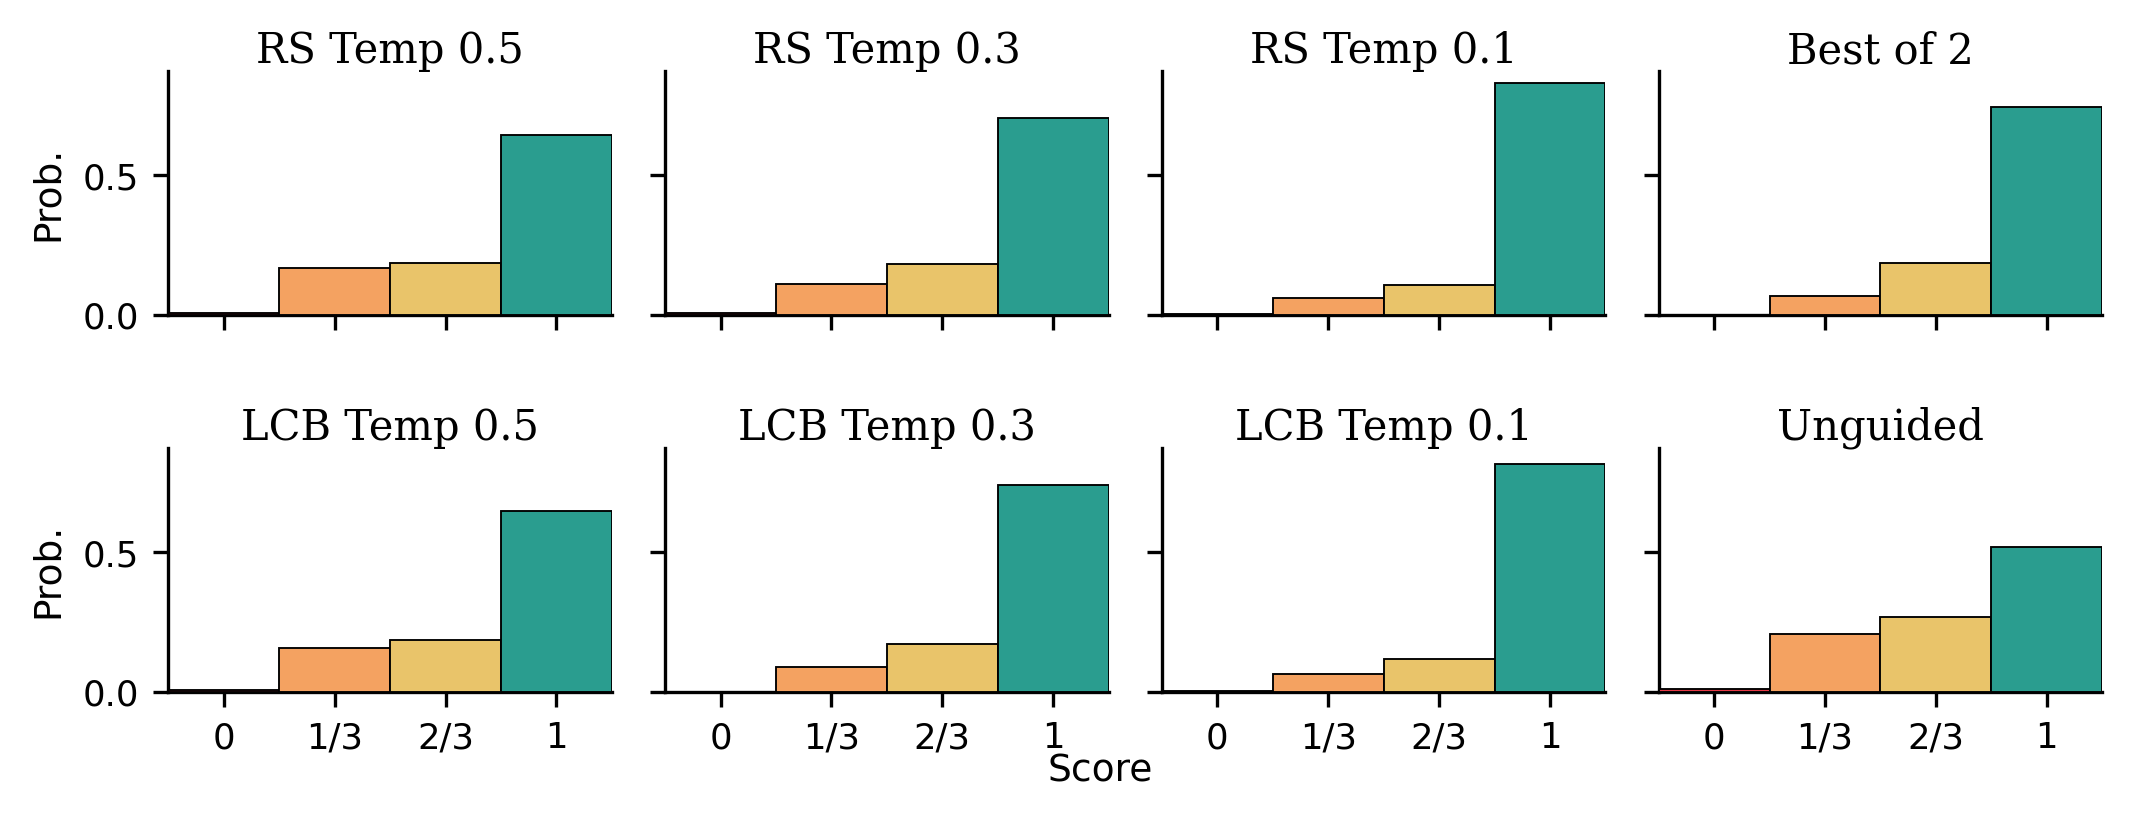

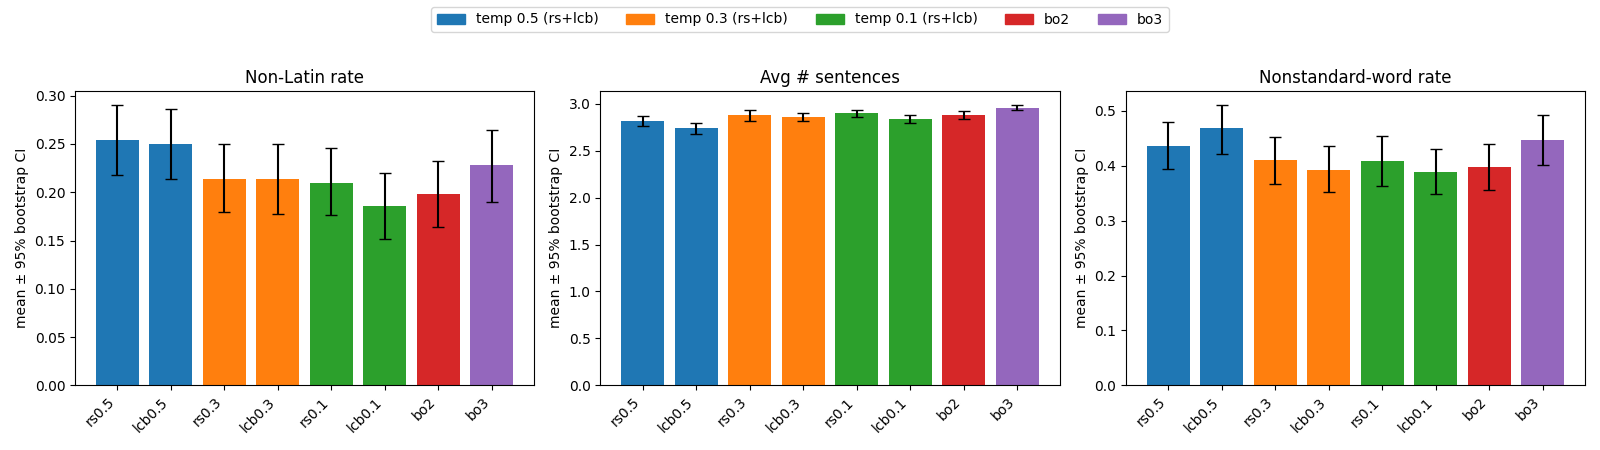

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'figures/regenerated/comparison_histograms.png')))
display(Image(filename=str(ROOT/'figures/regenerated/quality_barplots_3metrics/combined_3metric_barplots_horizontal.png')))
print('All new plots and tables:', ROOT/'figures/regenerated')

## 2. Inference — GPU


In [ ]:
!pip -q install -r requirements.txt

In [ ]:
# !python -u infer_lcb.py --run_id {NEW} --temp 0.5 --delta 0.1 --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p5 --num_samples 500 --sample_batch_size 250 --output_file reruns/lcb_alpha_0p5.json

In [ ]:
# !python -u infer_lcb.py --run_id {NEW} --temp 0.3 --delta 0.1 --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p3 --num_samples 500 --sample_batch_size 250 --output_file reruns/lcb_alpha_0p3.json

In [ ]:
# !python -u infer_lcb.py --run_id {NEW} --temp 0.1 --delta 0.1 --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p1 --num_samples 500 --sample_batch_size 250 --output_file reruns/lcb_alpha_0p1.json

### Sweep inference


In [ ]:
alpha, delta = 0.5, 0.5
a, d = str(alpha).replace('.', 'p'), str(delta).replace('.', 'p')
# !python -u infer_lcb.py --run_id {NEW} --temp {alpha} --delta {delta} --lcb_name sweeps/lcb_lambda_only_SYM_post_trained_temp_{a}_del_{d} --num_samples 500 --sample_batch_size 250 --output_file reruns/sweep_alpha_{a}_delta_{d}.json

### Reference methods


In [ ]:
# !python -u rejection_sampling.py --run_id {OLD} --reward_temp 0.5 --num_samples 500 --save_name reruns/rs_0p5.json
# !python -u rejection_sampling.py --run_id {OLD} --reward_temp 0.3 --num_samples 500 --save_name reruns/rs_0p3.json
# !python -u rejection_sampling.py --run_id {OLD} --reward_temp 0.1 --num_samples 500 --save_name reruns/rs_0p1.json
# !python -u bon.py --N 2 --num_samples 500 --output_file reruns/best_of_2_results.json
# !python -u bon.py --N 3 --num_samples 500 --output_file reruns/best_of_3_results.json
# !python -u bon.py --N 5 --num_samples 500 --output_file reruns/best_of_5_results.json
# !python -u bon.py --N 1 --num_samples 1000 --output_file reruns/unguided_results_1000.json


### SMC


In [ ]:
# !python -u sweep_smc.py --run_id {NEW} --reward_temp 0.1 --saved_grid configs/smc_grid.json --output_dir reruns/SMC

## 3. Training — GPU


In [ ]:
# !python -u llada_core_hide_prompt.py

# Uncomment this block to retrain on a separate copy of the saved inputs.
# import shutil
# from datetime import datetime
# TRAIN_RUN = 'rerun_' + datetime.now().strftime('%Y%m%d_%H%M%S')
# run_dir = ROOT/'data_runs'/TRAIN_RUN
# run_dir.mkdir()
# for name in [f'{NEW}_states.npy', f'{NEW}_rewards.npy', f'{NEW}_config.json']:
#     shutil.copy2(ROOT/'data_runs'/NEW/name, run_dir/name)
# PRETRAIN_ID = '20260205_223939_643203'
# pre = run_dir/'lcb_pretrain_data'/PRETRAIN_ID
# pre.mkdir(parents=True)
# for suffix in ['states.npy', 'rewards.npy', 'config.json']:
#     name = f'{PRETRAIN_ID}_{suffix}'
#     shutil.copy2(ROOT/'data_runs'/NEW/'lcb_pretrain_data'/PRETRAIN_ID/name, pre/name)
# print('Training run:', TRAIN_RUN)

In [ ]:
# !python -u nets_language_classifier.py {TRAIN_RUN} --dir data_runs --bs 1024 --epochs 10

In [ ]:
# !python -u pretrain_lcb.py {TRAIN_RUN} --samples 3000 --temp 0.5 --epochs 5 --pretrain_data_id {PRETRAIN_ID}

In [ ]:
# !python -u pretrain_lcb.py {TRAIN_RUN} --samples 3000 --temp 0.3 --epochs 8 --pretrain_data_id {PRETRAIN_ID}

In [ ]:
# !python -u pretrain_lcb.py {TRAIN_RUN} --samples 3000 --temp 0.1 --epochs 8 --pretrain_data_id {PRETRAIN_ID}

### LCB post-training


In [ ]:
# !python -u post_train_lcb.py --run_id {TRAIN_RUN} --reward_temp 0.5 --save_name lcb_lambda_only_SYM_post_trained_temp_0p5 --baseline_lr 0 --pretrained_lcb_name lcb_baseline_pretrained_temp_0p5 --accumulation_loops 1 --lambda_max 6 --sym 1 --train_batch_size 300 --delta 0.5 --eval_batch_size 250 --num_eval_loops 2

In [ ]:
# !python -u post_train_lcb.py --run_id {TRAIN_RUN} --reward_temp 0.3 --save_name lcb_lambda_only_SYM_post_trained_temp_0p3 --baseline_lr 0 --pretrained_lcb_name lcb_baseline_pretrained_temp_0p3 --accumulation_loops 1 --lambda_max 6 --sym 1 --train_batch_size 300 --delta 0.5 --eval_batch_size 250 --num_eval_loops 2

In [ ]:
# !python -u post_train_lcb.py --run_id {TRAIN_RUN} --reward_temp 0.1 --save_name lcb_lambda_only_SYM_post_trained_temp_0p1 --baseline_lr 0 --pretrained_lcb_name lcb_baseline_pretrained_temp_0p1 --accumulation_loops 1 --lambda_max 6 --sym 1 --train_batch_size 300 --delta 0.5 --eval_batch_size 250 --num_eval_loops 2

### Sweep post-training


In [ ]:
alpha, delta = 0.5, 0.9
a, d = str(alpha).replace('.', 'p'), str(delta).replace('.', 'p')
# !python -u post_train_lcb.py --run_id {TRAIN_RUN} --reward_temp {alpha} --delta {delta} --clip True --save_name sweeps/lcb_lambda_only_SYM_post_trained_temp_{a}_del_{d} --pretrained_lcb_name lcb_baseline_pretrained_temp_{a} --baseline_lr 0 --accumulation_loops 1 --lambda_max 10 --train_batch_size 300 --num_eval_loops 2 --eval_batch_size 250

## 4. Trajectory illustrations — GPU


In [ ]:
# !python -u analysis/plot_lcb_evolution.py --run_id {OLD} --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p1 --temp 0.1 --num_samples 12

In [ ]:
# !python -u analysis/plot_lcb_evolution.py --run_id {OLD} --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p3 --temp 0.3 --num_samples 12

In [ ]:
# !python -u analysis/plot_lcb_evolution.py --run_id {OLD} --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p5 --temp 0.5 --num_samples 12

## 5. Conditional coverage


In [ ]:
!python -u analysis/coverage_experiment.py --run_id {OLD} --lcb_name lcb_lambda_only_SYM_post_trained_temp_0p5_delta_0p1 --temp 0.5 --num_samples 50 --num_probes 20


config.json: 100% 480/480 [00:00<00:00, 3.11MB/s]
I0000 00:00:1793921773.443609    1658 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793921773.512482    1658 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793921777.024305    1658 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793921777.024907    1658 cudart_stub.cc:31] Could not find c

Regenerated coverage PNG/PDF figures in /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_20261105_233549_356445
Coverage: 31,989/32,000 (99.9656%)
Target: 90%


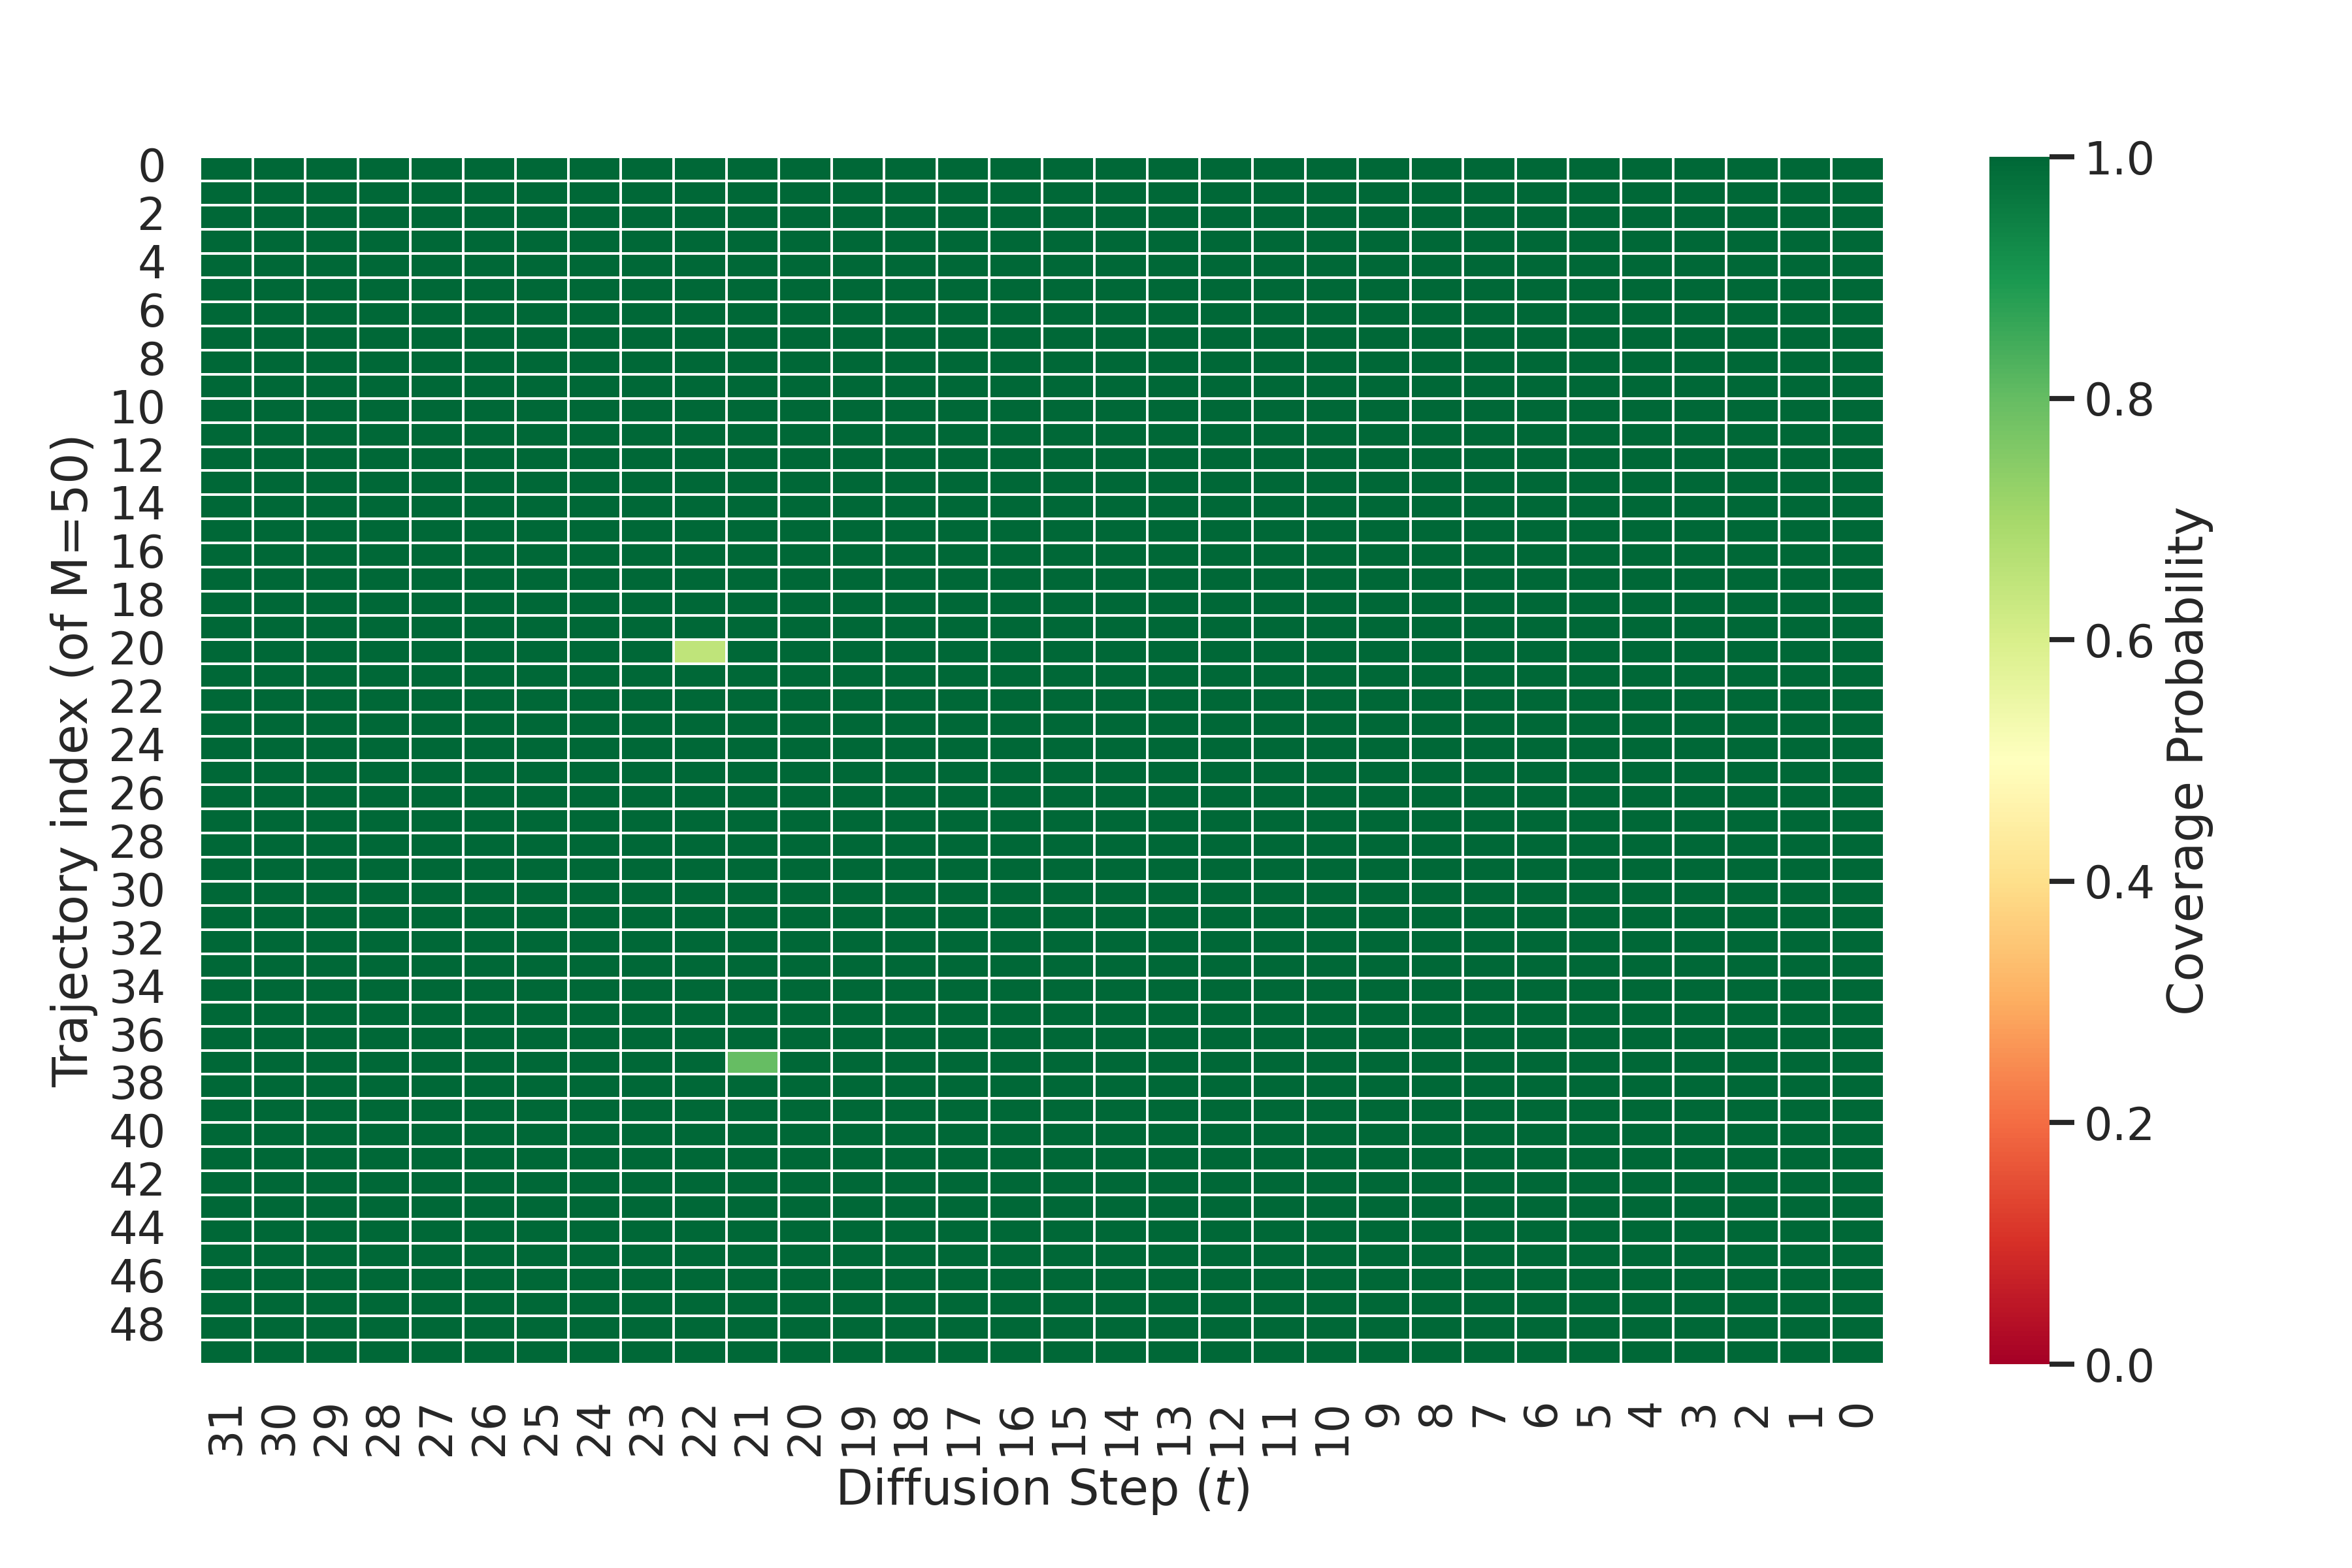

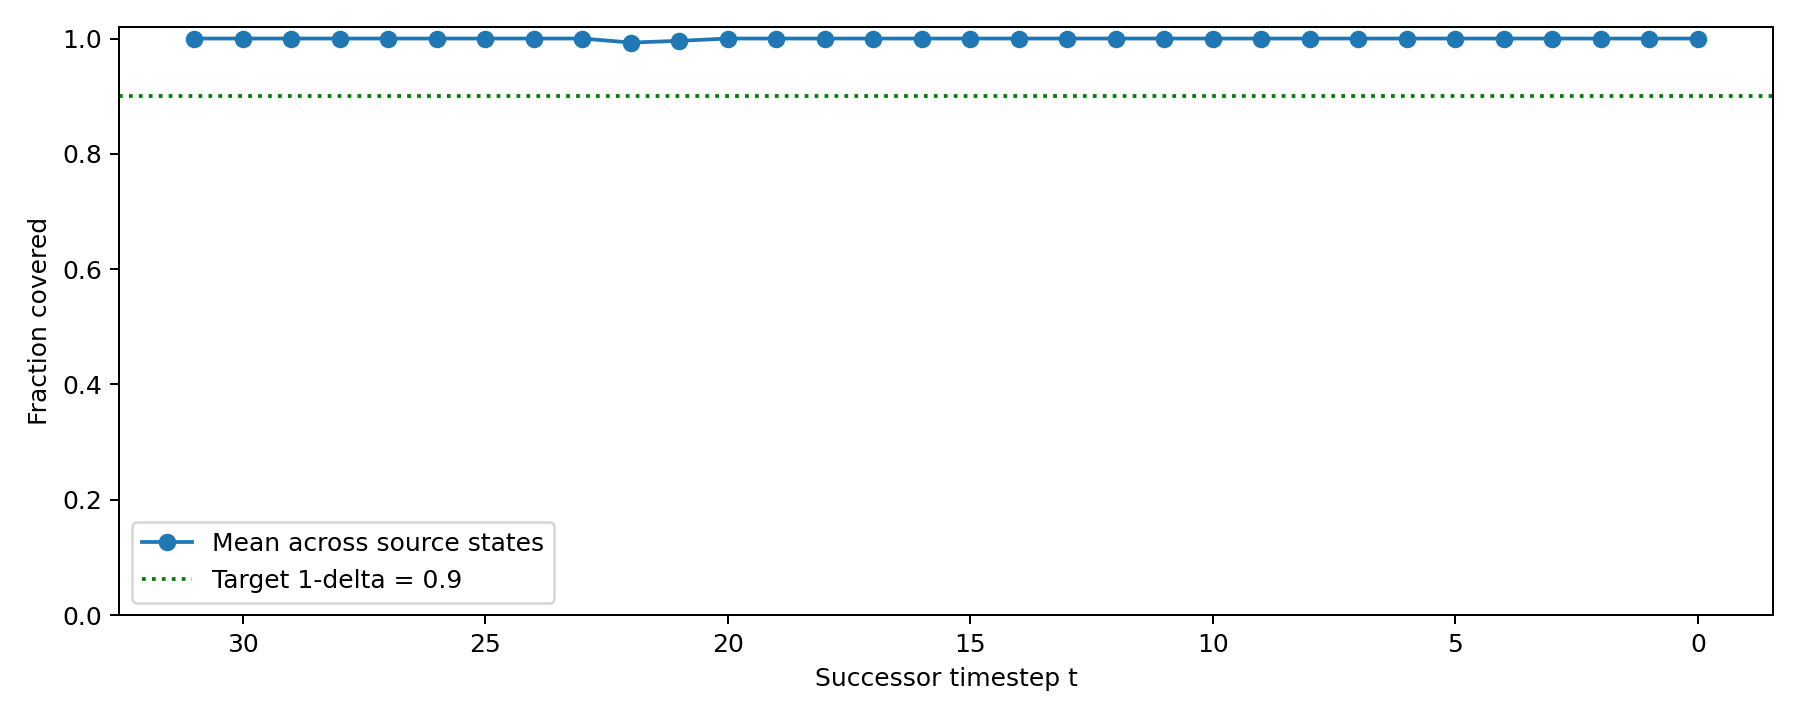

In [9]:
# Plot saved coverage results.
import json
import numpy as np
from IPython.display import Image, display
RUN_DIR = ROOT/'reruns/coverage_20261105_233549_356445'
!python -u analysis/replot_coverage.py --run_dir {RUN_DIR}
summary = json.loads((RUN_DIR/'coverage_summary.json').read_text())
with np.load(RUN_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    print(f"Coverage: {covered.sum():,}/{covered.size:,} ({100*covered.mean():.4f}%)")
print(f"Target: {100*summary['target_coverage']:.0f}%")
display(Image(filename=str(RUN_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(RUN_DIR/'coverage_mean.png'), width=900))


In [11]:
# Coverage: alpha=0.3, delta=0.5.
import json, torch
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
COV03_RUN = '20260205_195651_634076'
COV03_LCB = 'lcb_lambda_only_SYM_post_trained_temp_0p3'
checkpoint_path = ROOT/'data_runs'/COV03_RUN/f'{COV03_LCB}.pt'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
training = json.loads(checkpoint_path.with_name(f'{COV03_LCB}_results.json').read_text())
print('Checkpoint:', checkpoint_path)
print('Alpha:', training['reward_temp'], 'Delta:', checkpoint['config']['delta'])
print('Calibrated transitions:', sum(bool(checkpoint['trained_t'][t]) and checkpoint['taus'][t] is not None for t in range(1,33)))
assert training['reward_temp'] == 0.3 and checkpoint['config']['delta'] == 0.5
del checkpoint

from datetime import datetime, timezone
import shutil, subprocess, sys
COV03_DIR = ROOT/'reruns'/('coverage_a0p3_d0p5_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
print('Output:', COV03_DIR, flush=True)
!python -u "{ROOT}/analysis/coverage_experiment.py" --run_id {COV03_RUN} --lcb_name {COV03_LCB} --temp 0.3 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV03_DIR}"
assert (COV03_DIR/'coverage_summary.json').is_file()
(COV03_DIR/'command.txt').write_text(f'python -u analysis/coverage_experiment.py --run_id {COV03_RUN} --lcb_name {COV03_LCB} --temp 0.3 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV03_DIR}"\n')
(COV03_DIR/'environment.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
shutil.copy2(ROOT/'analysis/coverage_experiment.py',COV03_DIR/'inference_script.py')


Checkpoint: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20260205_195651_634076/lcb_lambda_only_SYM_post_trained_temp_0p3.pt
Alpha: 0.3 Delta: 0.5
Calibrated transitions: 32
Output: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p5_20261106_010020_909165
config.json: 100% 480/480 [00:00<00:00, 1.81MB/s]
I0000 00:00:1793926832.919090    7750 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793926832.991461    7750 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793926835.854025    7750 port.cc:153] oneDN

PosixPath('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p5_20261106_010020_909165/inference_script.py')

Coverage: 30,884/32,000 (96.5125%)
Target: 50%
State–timestep pairs below target: 42/1,600
Minimum state–timestep coverage: 0.0%
Saved in: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p5_20261106_010020_909165


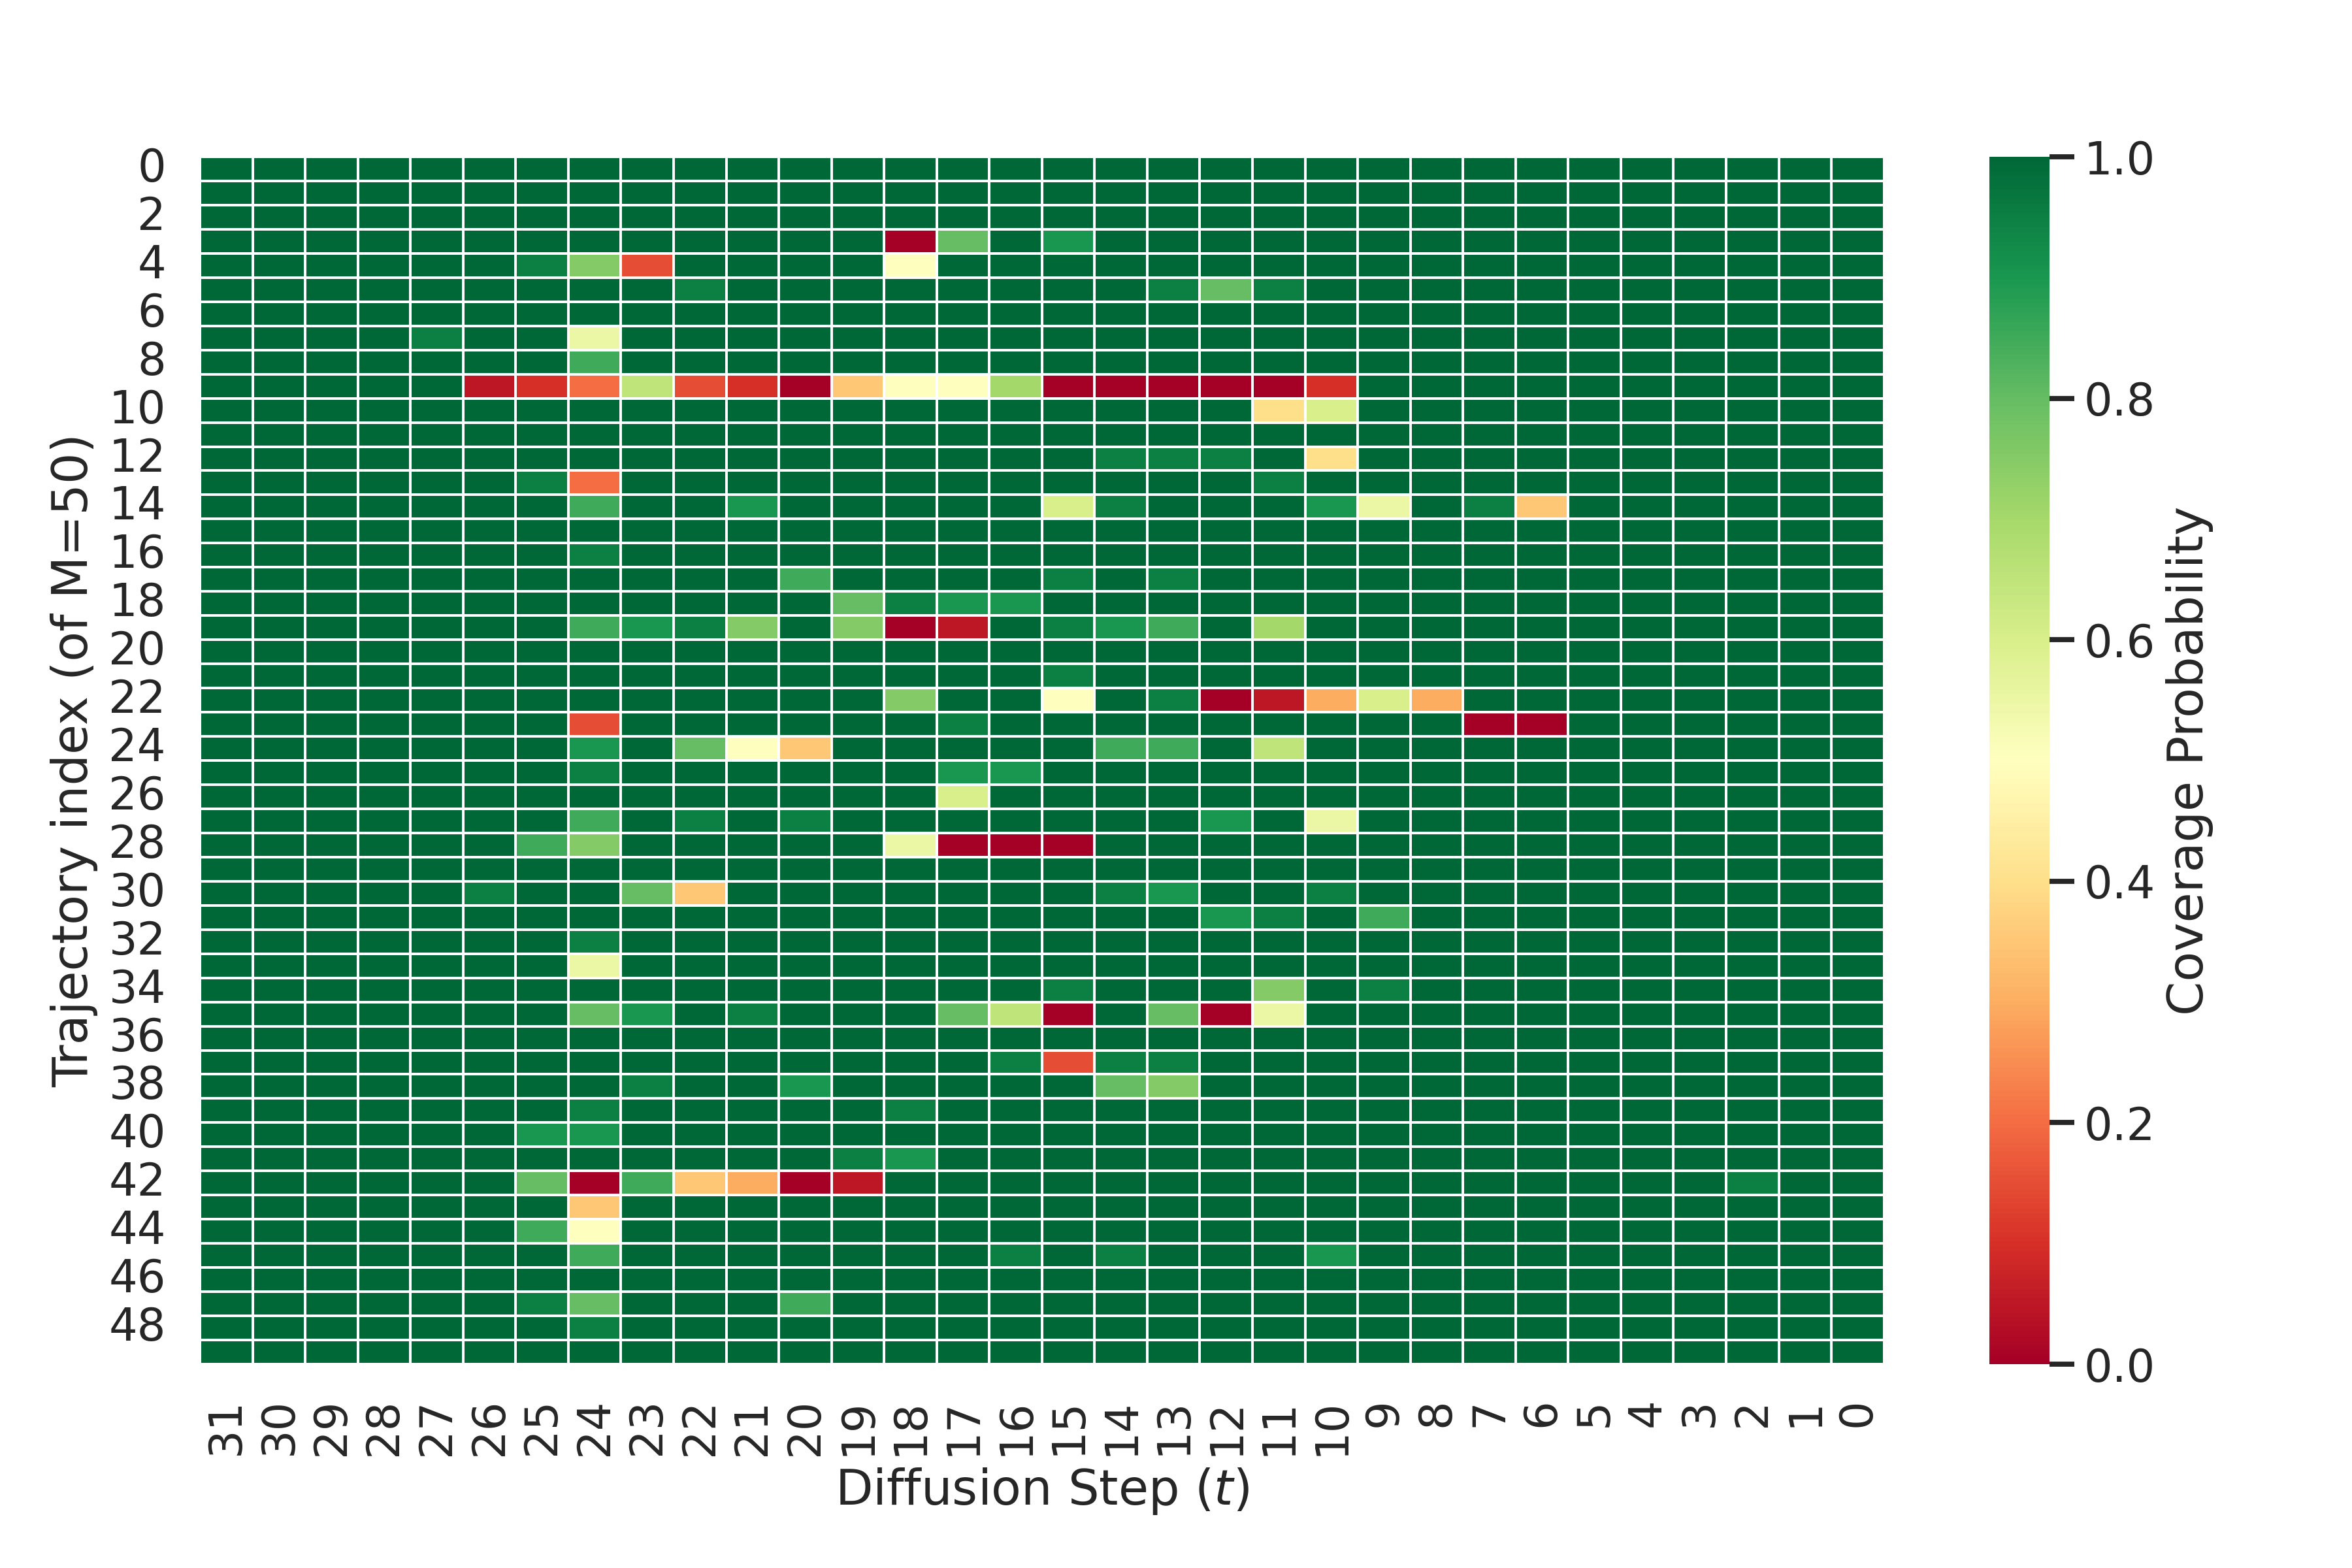

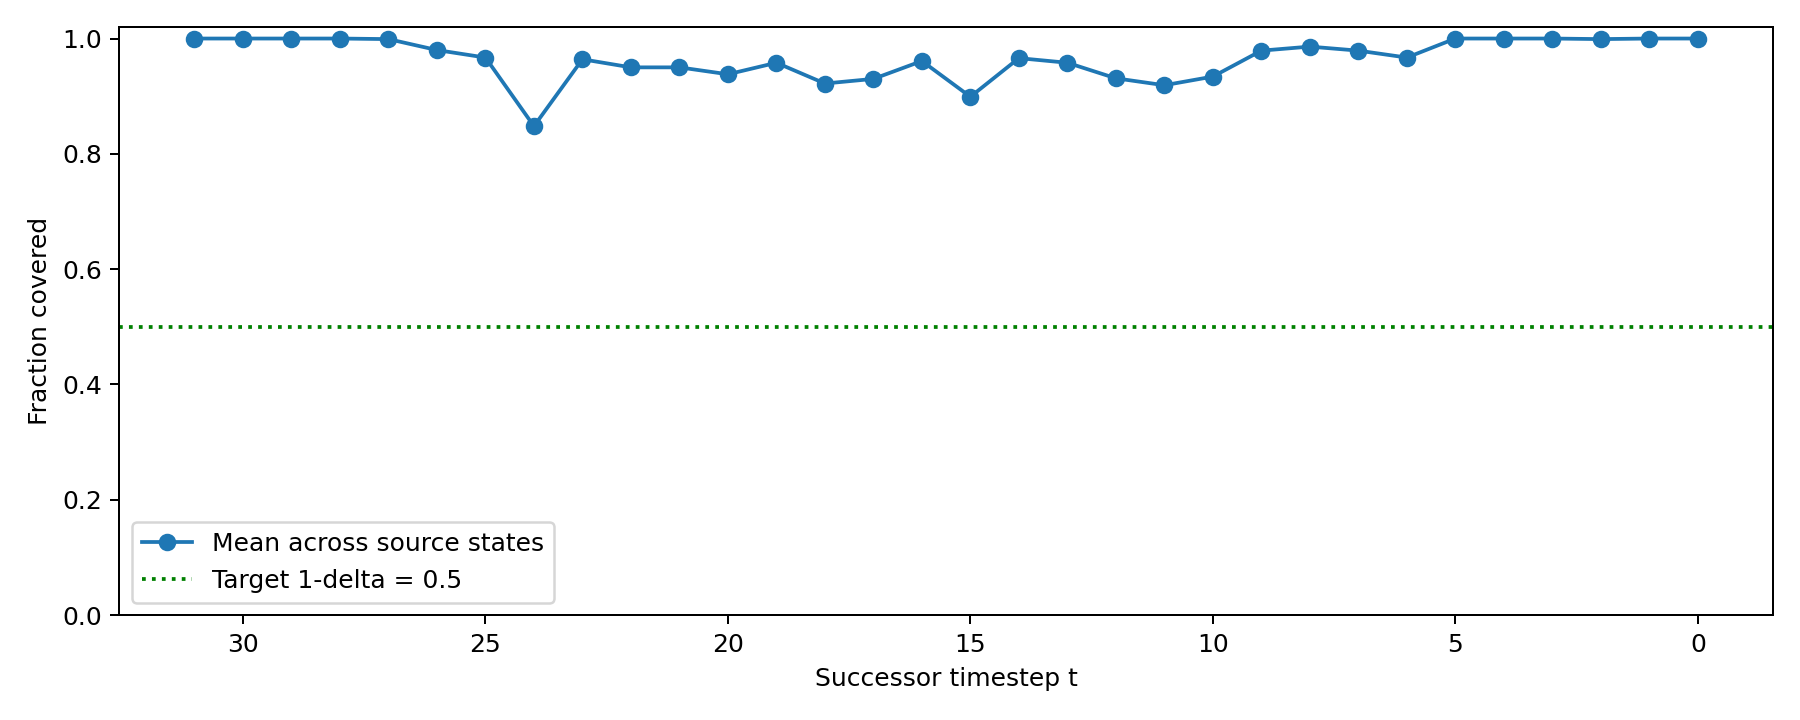

In [12]:
# Saved coverage results: alpha=0.3, delta=0.5.
import json
import numpy as np
from pathlib import Path
from IPython.display import Image, display
COV03_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p5_20261106_010020_909165')
summary03 = json.loads((COV03_DIR/'coverage_summary.json').read_text())
with np.load(COV03_DIR/'coverage.npz') as saved:
    covered03 = saved['covered']
    coverage03 = saved['coverage']
    assert np.array_equal(covered03, saved['log_values'] <= saved['thresholds'][:, :, None])
    assert np.array_equal(coverage03, covered03.mean(axis=2))
assert summary03['alpha'] == 0.3 and summary03['delta'] == 0.5
print(f"Coverage: {covered03.sum():,}/{covered03.size:,} ({100*covered03.mean():.4f}%)")
print(f"Target: {100*summary03['target_coverage']:.0f}%")
print(f"State–timestep pairs below target: {(coverage03 < summary03['target_coverage']).sum():,}/{coverage03.size:,}")
print(f"Minimum state–timestep coverage: {100*coverage03.min():.1f}%")
print('Saved in:', COV03_DIR)
display(Image(filename=str(COV03_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(COV03_DIR/'coverage_mean.png'), width=900))


In [14]:
# Coverage table at c=1/2: 10/20 proposals counts as passing.
import csv
import numpy as np
from pathlib import Path
from IPython.display import Markdown, display

COV03_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p5_20261106_010020_909165')
with np.load(COV03_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    source_steps = saved['source_steps']
    successor_steps = saved['successor_steps']

num_sources, num_probes = covered.shape[1:]
passing = (2 * covered.sum(axis=2) >= num_probes).sum(axis=1)
rows = [
    (int(s), int(t), int(n), num_sources, (num_sources-int(n))/num_sources)
    for s, t, n in zip(source_steps, successor_steps, passing)
]
csv_path = COV03_DIR/'coverage_zeta_c0p5.csv'
with csv_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_step', 'successor_step', 'passing_trajectories', 'num_trajectories', 'zeta'])
    writer.writerows(rows)

table = '| Transition | Trajectories with coverage ≥50% | ζ |\n|---|---:|---:|\n'
table += '\n'.join(f'| {s} → {t} | {n}/{total} | {zeta:.2f} |' for s, t, n, total, zeta in rows)
display(Markdown(table))
print(f'Worst-timestep zeta: {max(row[-1] for row in rows):.2f}')
print('Saved:', csv_path)
x

| Transition | Trajectories with coverage ≥50% | ζ |
|---|---:|---:|
| 32 → 31 | 50/50 | 0.00 |
| 31 → 30 | 50/50 | 0.00 |
| 30 → 29 | 50/50 | 0.00 |
| 29 → 28 | 50/50 | 0.00 |
| 28 → 27 | 50/50 | 0.00 |
| 27 → 26 | 49/50 | 0.02 |
| 26 → 25 | 49/50 | 0.02 |
| 25 → 24 | 45/50 | 0.10 |
| 24 → 23 | 49/50 | 0.02 |
| 23 → 22 | 47/50 | 0.06 |
| 22 → 21 | 48/50 | 0.04 |
| 21 → 20 | 47/50 | 0.06 |
| 20 → 19 | 48/50 | 0.04 |
| 19 → 18 | 48/50 | 0.04 |
| 18 → 17 | 48/50 | 0.04 |
| 17 → 16 | 49/50 | 0.02 |
| 16 → 15 | 46/50 | 0.08 |
| 15 → 14 | 49/50 | 0.02 |
| 14 → 13 | 49/50 | 0.02 |
| 13 → 12 | 47/50 | 0.06 |
| 12 → 11 | 47/50 | 0.06 |
| 11 → 10 | 47/50 | 0.06 |
| 10 → 9 | 50/50 | 0.00 |
| 9 → 8 | 49/50 | 0.02 |
| 8 → 7 | 49/50 | 0.02 |
| 7 → 6 | 48/50 | 0.04 |
| 6 → 5 | 50/50 | 0.00 |
| 5 → 4 | 50/50 | 0.00 |
| 4 → 3 | 50/50 | 0.00 |
| 3 → 2 | 50/50 | 0.00 |
| 2 → 1 | 50/50 | 0.00 |
| 1 → 0 | 50/50 | 0.00 |

Worst-timestep zeta: 0.10
Saved: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p5_20261106_010020_909165/coverage_zeta_c0p5.csv


In [16]:
# Coverage: alpha=0.5, delta=0.1.
from pathlib import Path
from datetime import datetime, timezone
import torch, shutil, subprocess, sys

ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
COV05_RUN = '20251224_233551_699407'
COV05_LCB = 'lcb_lambda_only_SYM_post_trained_temp_0p5_delta_0p1'
checkpoint_path = ROOT/'data_runs'/COV05_RUN/f'{COV05_LCB}.pt'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
assert checkpoint['config']['delta'] == 0.1
print('Checkpoint:', checkpoint_path)
print('Alpha: 0.5; delta:', checkpoint['config']['delta'])
del checkpoint

COV05_DIR = ROOT/'reruns'/('coverage_a0p5_d0p1_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
print('Output:', COV05_DIR, flush=True)
!python -u "{ROOT}/analysis/coverage_experiment.py" --run_id {COV05_RUN} --lcb_name {COV05_LCB} --temp 0.5 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV05_DIR}"
assert (COV05_DIR/'coverage_summary.json').is_file()
(COV05_DIR/'command.txt').write_text(f'python -u analysis/coverage_experiment.py --run_id {COV05_RUN} --lcb_name {COV05_LCB} --temp 0.5 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV05_DIR}"\n')
(COV05_DIR/'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
shutil.copy2(ROOT/'analysis/coverage_experiment.py', COV05_DIR/'inference_script.py')


Checkpoint: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20251224_233551_699407/lcb_lambda_only_SYM_post_trained_temp_0p5_delta_0p1.pt
Alpha: 0.5; delta: 0.1
Output: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p1_20261106_053332_457781
I0000 00:00:1793943219.042103   75322 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793943219.111309   75322 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793943221.659777   75322 port.cc:153] oneDNN custom operations are on. You may see slightly different numeric

PosixPath('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p1_20261106_053332_457781/inference_script.py')

Coverage: 31,989/32,000 (99.9656%)
Target: 90%
State–timestep pairs below target: 2/1,600
Minimum state–timestep coverage: 65.0%
Saved in: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p1_20261106_053332_457781


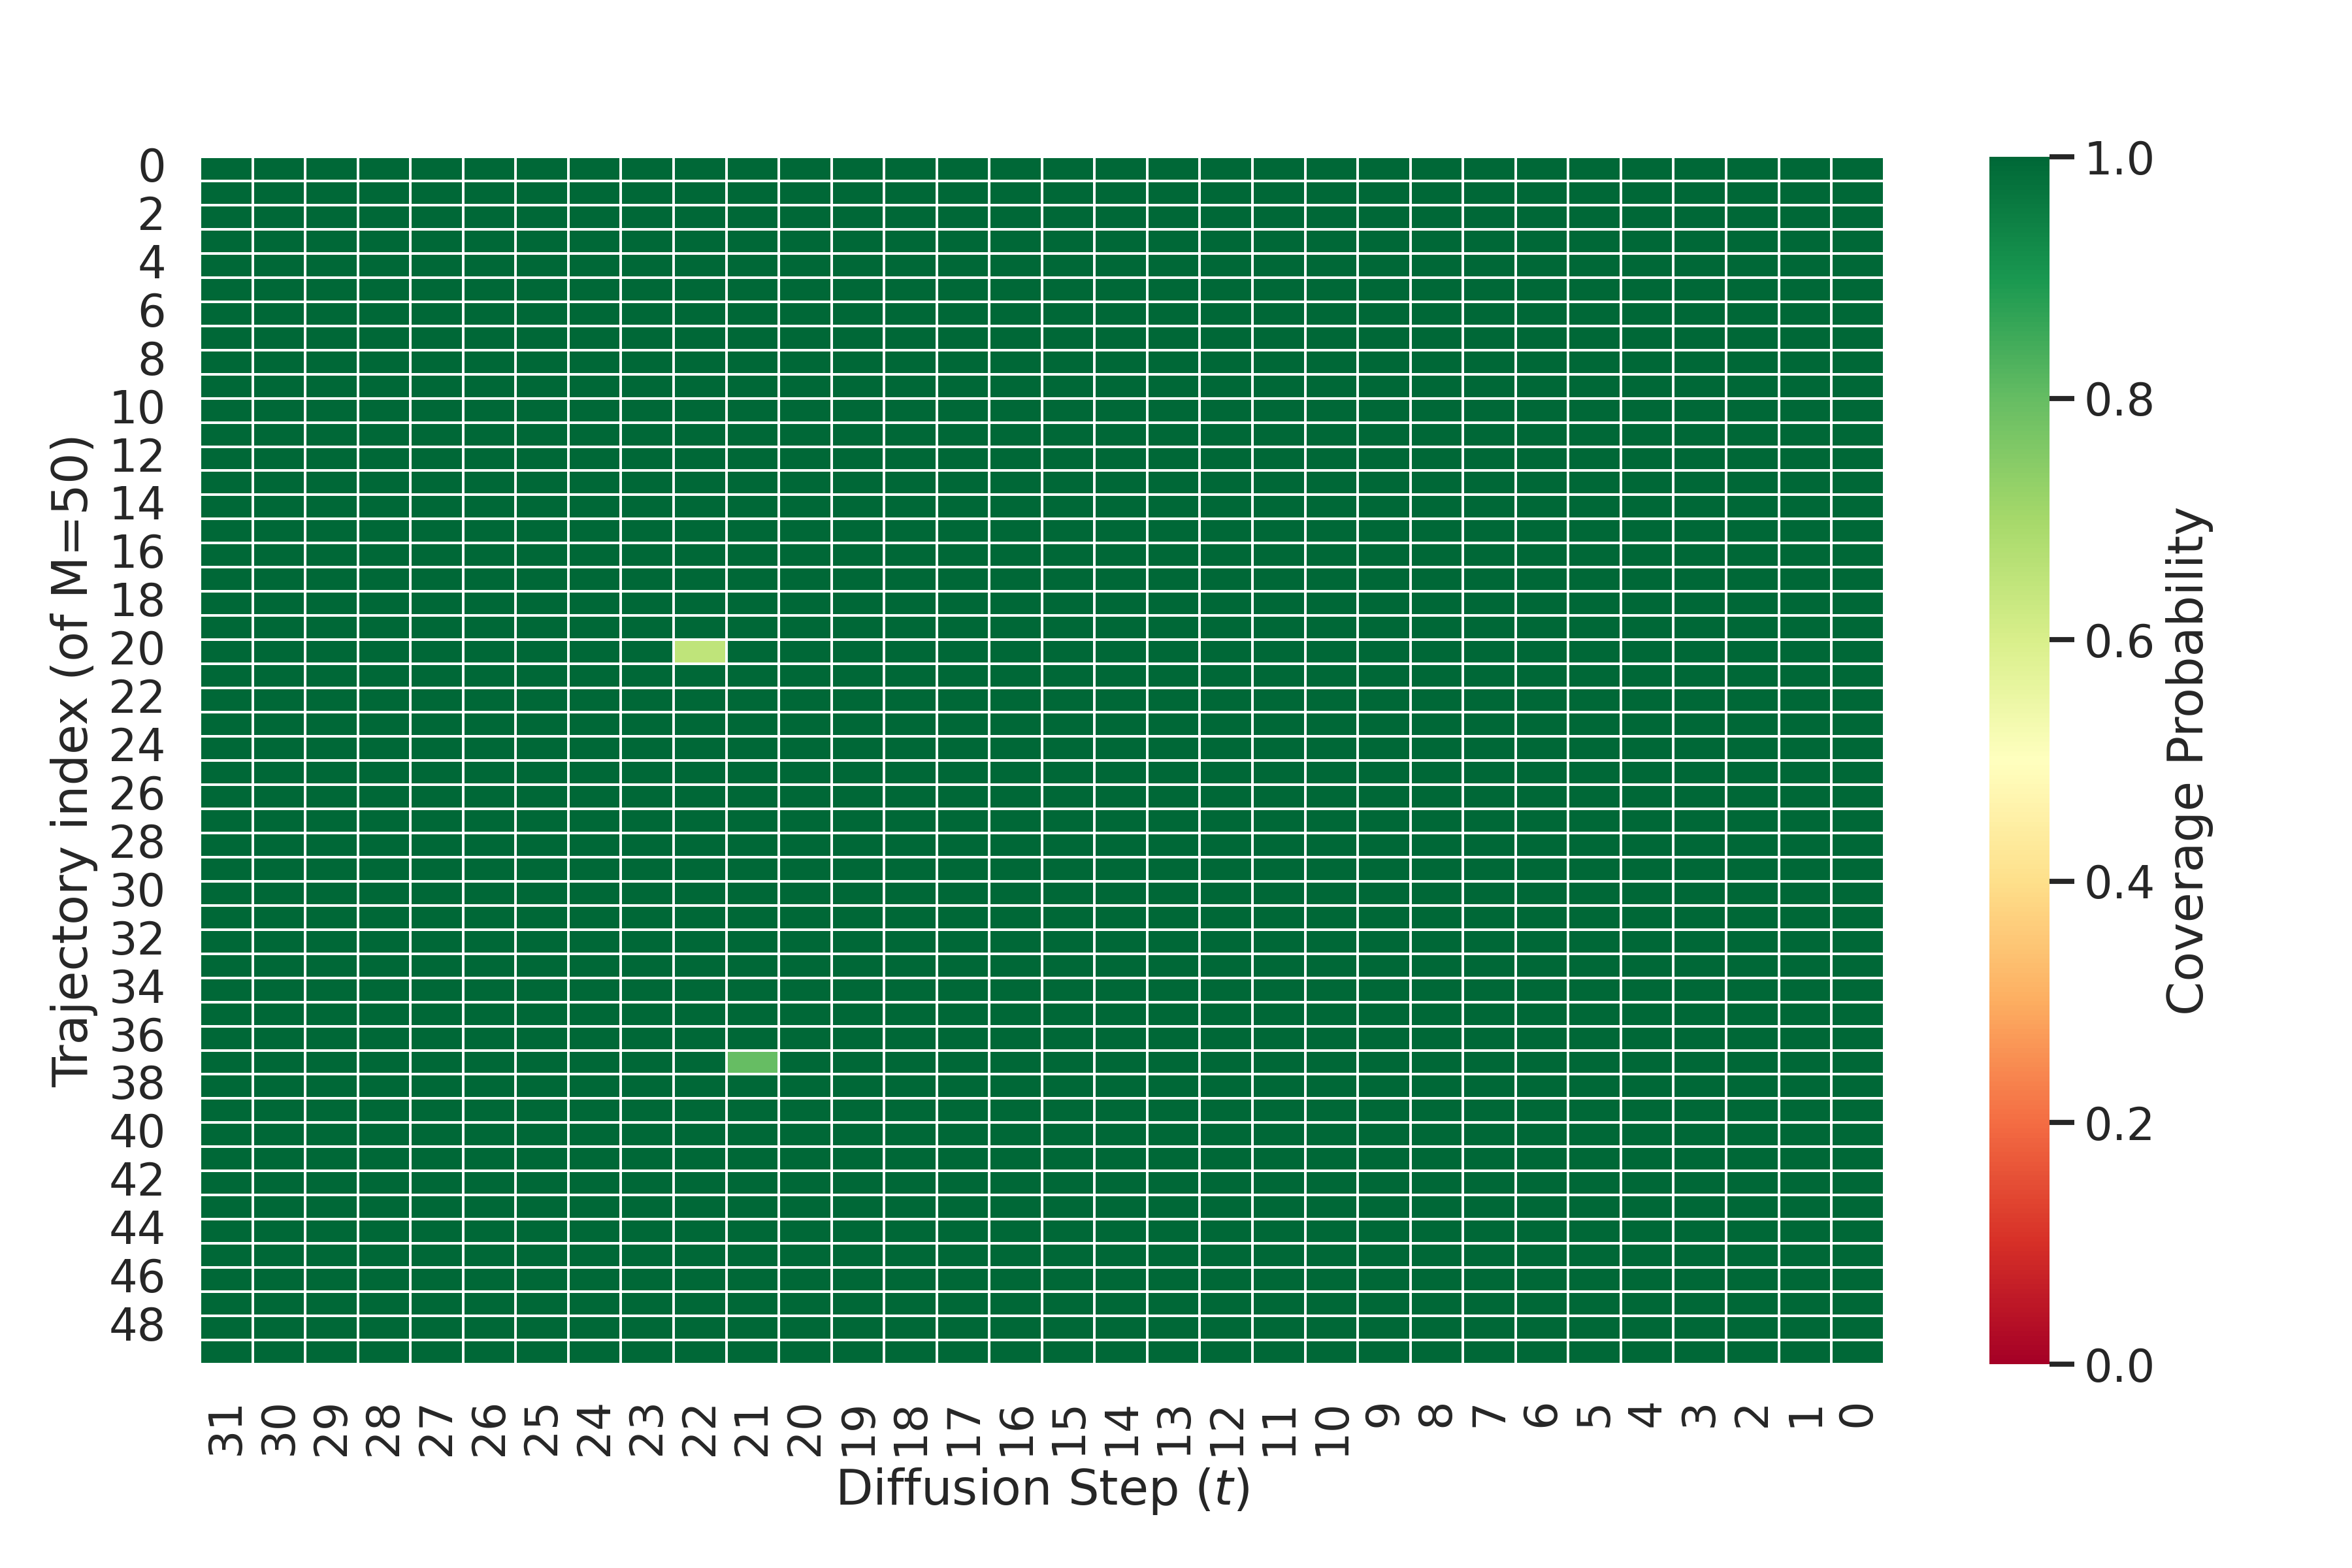

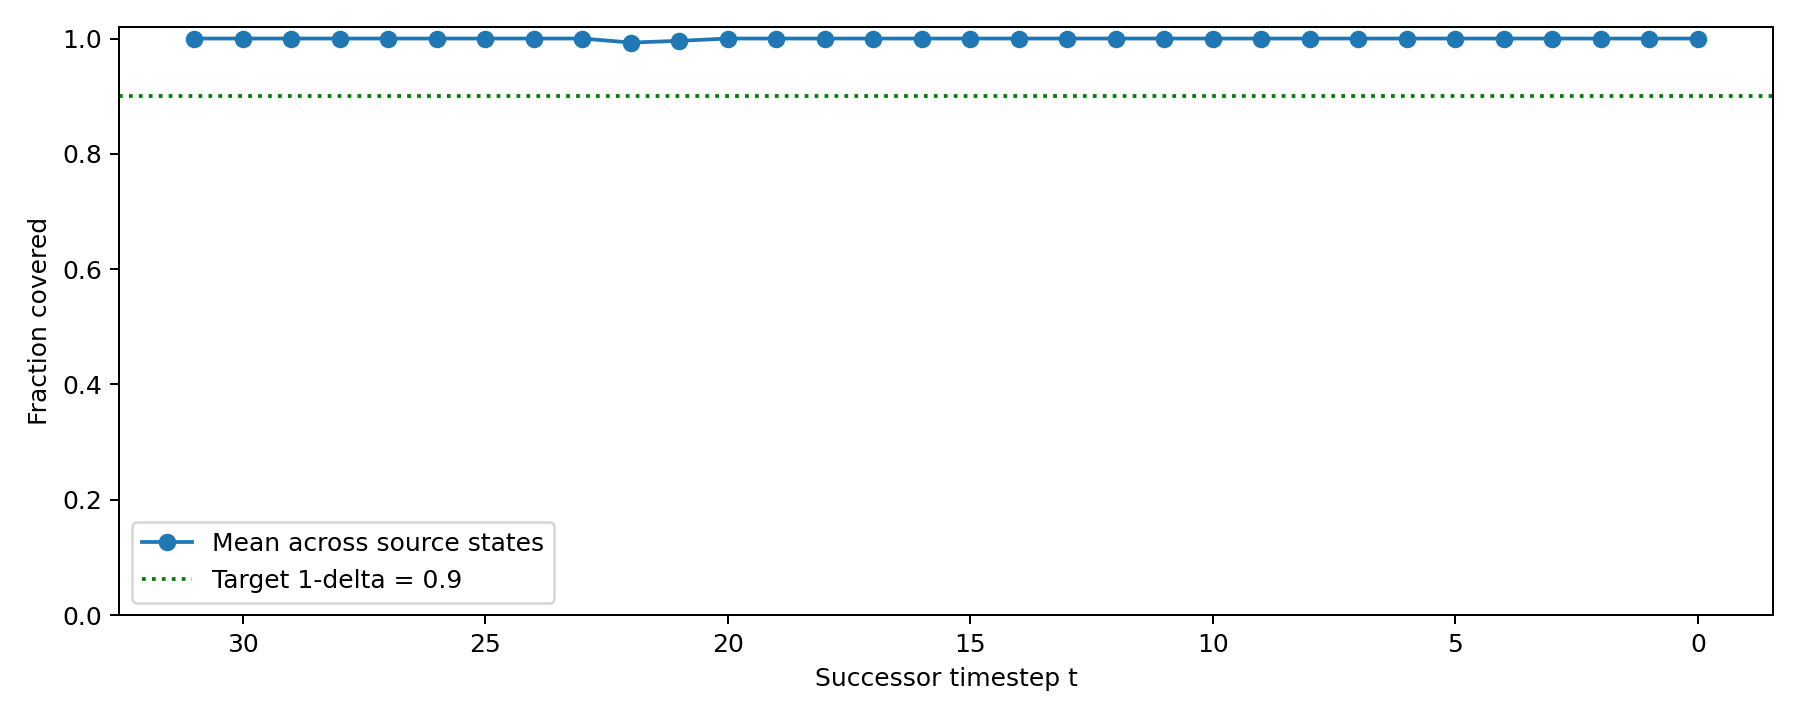

In [17]:
# Saved coverage results: alpha=0.5, delta=0.1.
import json
import numpy as np
from pathlib import Path
from IPython.display import Image, display

COV05_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p1_20261106_053332_457781')
summary05 = json.loads((COV05_DIR/'coverage_summary.json').read_text())
with np.load(COV05_DIR/'coverage.npz') as saved:
    covered05 = saved['covered']
    coverage05 = saved['coverage']
    assert np.array_equal(covered05, saved['log_values'] <= saved['thresholds'][:, :, None])
    assert np.array_equal(coverage05, covered05.mean(axis=2))
assert summary05['alpha'] == 0.5 and summary05['delta'] == 0.1
print(f"Coverage: {covered05.sum():,}/{covered05.size:,} ({100*covered05.mean():.4f}%)")
print(f"Target: {100*summary05['target_coverage']:.0f}%")
print(f"State–timestep pairs below target: {(coverage05 < summary05['target_coverage']).sum():,}/{coverage05.size:,}")
print(f"Minimum state–timestep coverage: {100*coverage05.min():.1f}%")
print('Saved in:', COV05_DIR)
display(Image(filename=str(COV05_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(COV05_DIR/'coverage_mean.png'), width=900))


In [18]:
# Coverage table at c=1/2: 10/20 proposals counts as passing.
import csv
import numpy as np
from pathlib import Path
from IPython.display import Markdown, display

COV05_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p1_20261106_053332_457781')
with np.load(COV05_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    source_steps = saved['source_steps']
    successor_steps = saved['successor_steps']

num_sources, num_probes = covered.shape[1:]
passing = (2 * covered.sum(axis=2) >= num_probes).sum(axis=1)
rows = [
    (int(s), int(t), int(n), num_sources, (num_sources-int(n))/num_sources)
    for s, t, n in zip(source_steps, successor_steps, passing)
]
csv_path = COV05_DIR/'coverage_zeta_c0p5.csv'
with csv_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_step', 'successor_step', 'passing_trajectories', 'num_trajectories', 'zeta'])
    writer.writerows(rows)

table = '| Transition | Trajectories with coverage ≥50% | ζ |\n|---|---:|---:|\n'
table += '\n'.join(f'| {s} → {t} | {n}/{total} | {zeta:.2f} |' for s, t, n, total, zeta in rows)
display(Markdown(table))
print(f'Worst-timestep zeta: {max(row[-1] for row in rows):.2f}')
print(f'Sum of zetas: {sum(row[-1] for row in rows):.2f}')
print('Saved:', csv_path)


| Transition | Trajectories with coverage ≥50% | ζ |
|---|---:|---:|
| 32 → 31 | 50/50 | 0.00 |
| 31 → 30 | 50/50 | 0.00 |
| 30 → 29 | 50/50 | 0.00 |
| 29 → 28 | 50/50 | 0.00 |
| 28 → 27 | 50/50 | 0.00 |
| 27 → 26 | 50/50 | 0.00 |
| 26 → 25 | 50/50 | 0.00 |
| 25 → 24 | 50/50 | 0.00 |
| 24 → 23 | 50/50 | 0.00 |
| 23 → 22 | 50/50 | 0.00 |
| 22 → 21 | 50/50 | 0.00 |
| 21 → 20 | 50/50 | 0.00 |
| 20 → 19 | 50/50 | 0.00 |
| 19 → 18 | 50/50 | 0.00 |
| 18 → 17 | 50/50 | 0.00 |
| 17 → 16 | 50/50 | 0.00 |
| 16 → 15 | 50/50 | 0.00 |
| 15 → 14 | 50/50 | 0.00 |
| 14 → 13 | 50/50 | 0.00 |
| 13 → 12 | 50/50 | 0.00 |
| 12 → 11 | 50/50 | 0.00 |
| 11 → 10 | 50/50 | 0.00 |
| 10 → 9 | 50/50 | 0.00 |
| 9 → 8 | 50/50 | 0.00 |
| 8 → 7 | 50/50 | 0.00 |
| 7 → 6 | 50/50 | 0.00 |
| 6 → 5 | 50/50 | 0.00 |
| 5 → 4 | 50/50 | 0.00 |
| 4 → 3 | 50/50 | 0.00 |
| 3 → 2 | 50/50 | 0.00 |
| 2 → 1 | 50/50 | 0.00 |
| 1 → 0 | 50/50 | 0.00 |

Worst-timestep zeta: 0.00
Sum of zetas: 0.00
Saved: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p1_20261106_053332_457781/coverage_zeta_c0p5.csv


In [22]:
# Coverage: alpha=0.3, delta=0.3.
from pathlib import Path
from datetime import datetime, timezone
import json, torch, shutil, subprocess, sys

ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
COV033_RUN = '20260205_195651_634076'
COV033_LCB = 'sweeps/lcb_lambda_only_SYM_post_trained_temp_0p3_del_0p3'
checkpoint_path = ROOT/'data_runs'/COV033_RUN/f'{COV033_LCB}.pt'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
training = json.loads(checkpoint_path.with_name(checkpoint_path.stem+'_results.json').read_text())
assert checkpoint['config']['delta'] == 0.3 and training['reward_temp'] == 0.3
print('Checkpoint:', checkpoint_path)
print('Alpha:', training['reward_temp'], 'Delta:', checkpoint['config']['delta'])
print('Calibrated transitions:', sum(bool(checkpoint['trained_t'][t]) and checkpoint['taus'][t] is not None for t in range(1,33)))
del checkpoint

COV033_DIR = ROOT/'reruns'/('coverage_a0p3_d0p3_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
print('Output:', COV033_DIR, flush=True)
!python -u "{ROOT}/analysis/coverage_experiment.py" --run_id {COV033_RUN} --lcb_name {COV033_LCB} --temp 0.3 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV033_DIR}"
assert (COV033_DIR/'coverage_summary.json').is_file()
(COV033_DIR/'command.txt').write_text(f'python -u analysis/coverage_experiment.py --run_id {COV033_RUN} --lcb_name {COV033_LCB} --temp 0.3 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV033_DIR}"\n')
(COV033_DIR/'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
shutil.copy2(ROOT/'analysis/coverage_experiment.py', COV033_DIR/'inference_script.py')


Checkpoint: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20260205_195651_634076/sweeps/lcb_lambda_only_SYM_post_trained_temp_0p3_del_0p3.pt
Alpha: 0.3 Delta: 0.3
Calibrated transitions: 32
Output: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p3_20261106_054849_004041
I0000 00:00:1793944134.917787   79410 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793944134.989979   79410 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793944137.526441   79410 port.cc:153] oneDNN custom operations are on. You may

PosixPath('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p3_20261106_054849_004041/inference_script.py')

Coverage: 31,136/32,000 (97.3000%)
Target: 70%
State–timestep pairs below target: 46/1,600
Minimum state–timestep coverage: 0.0%
Saved in: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p3_20261106_054849_004041


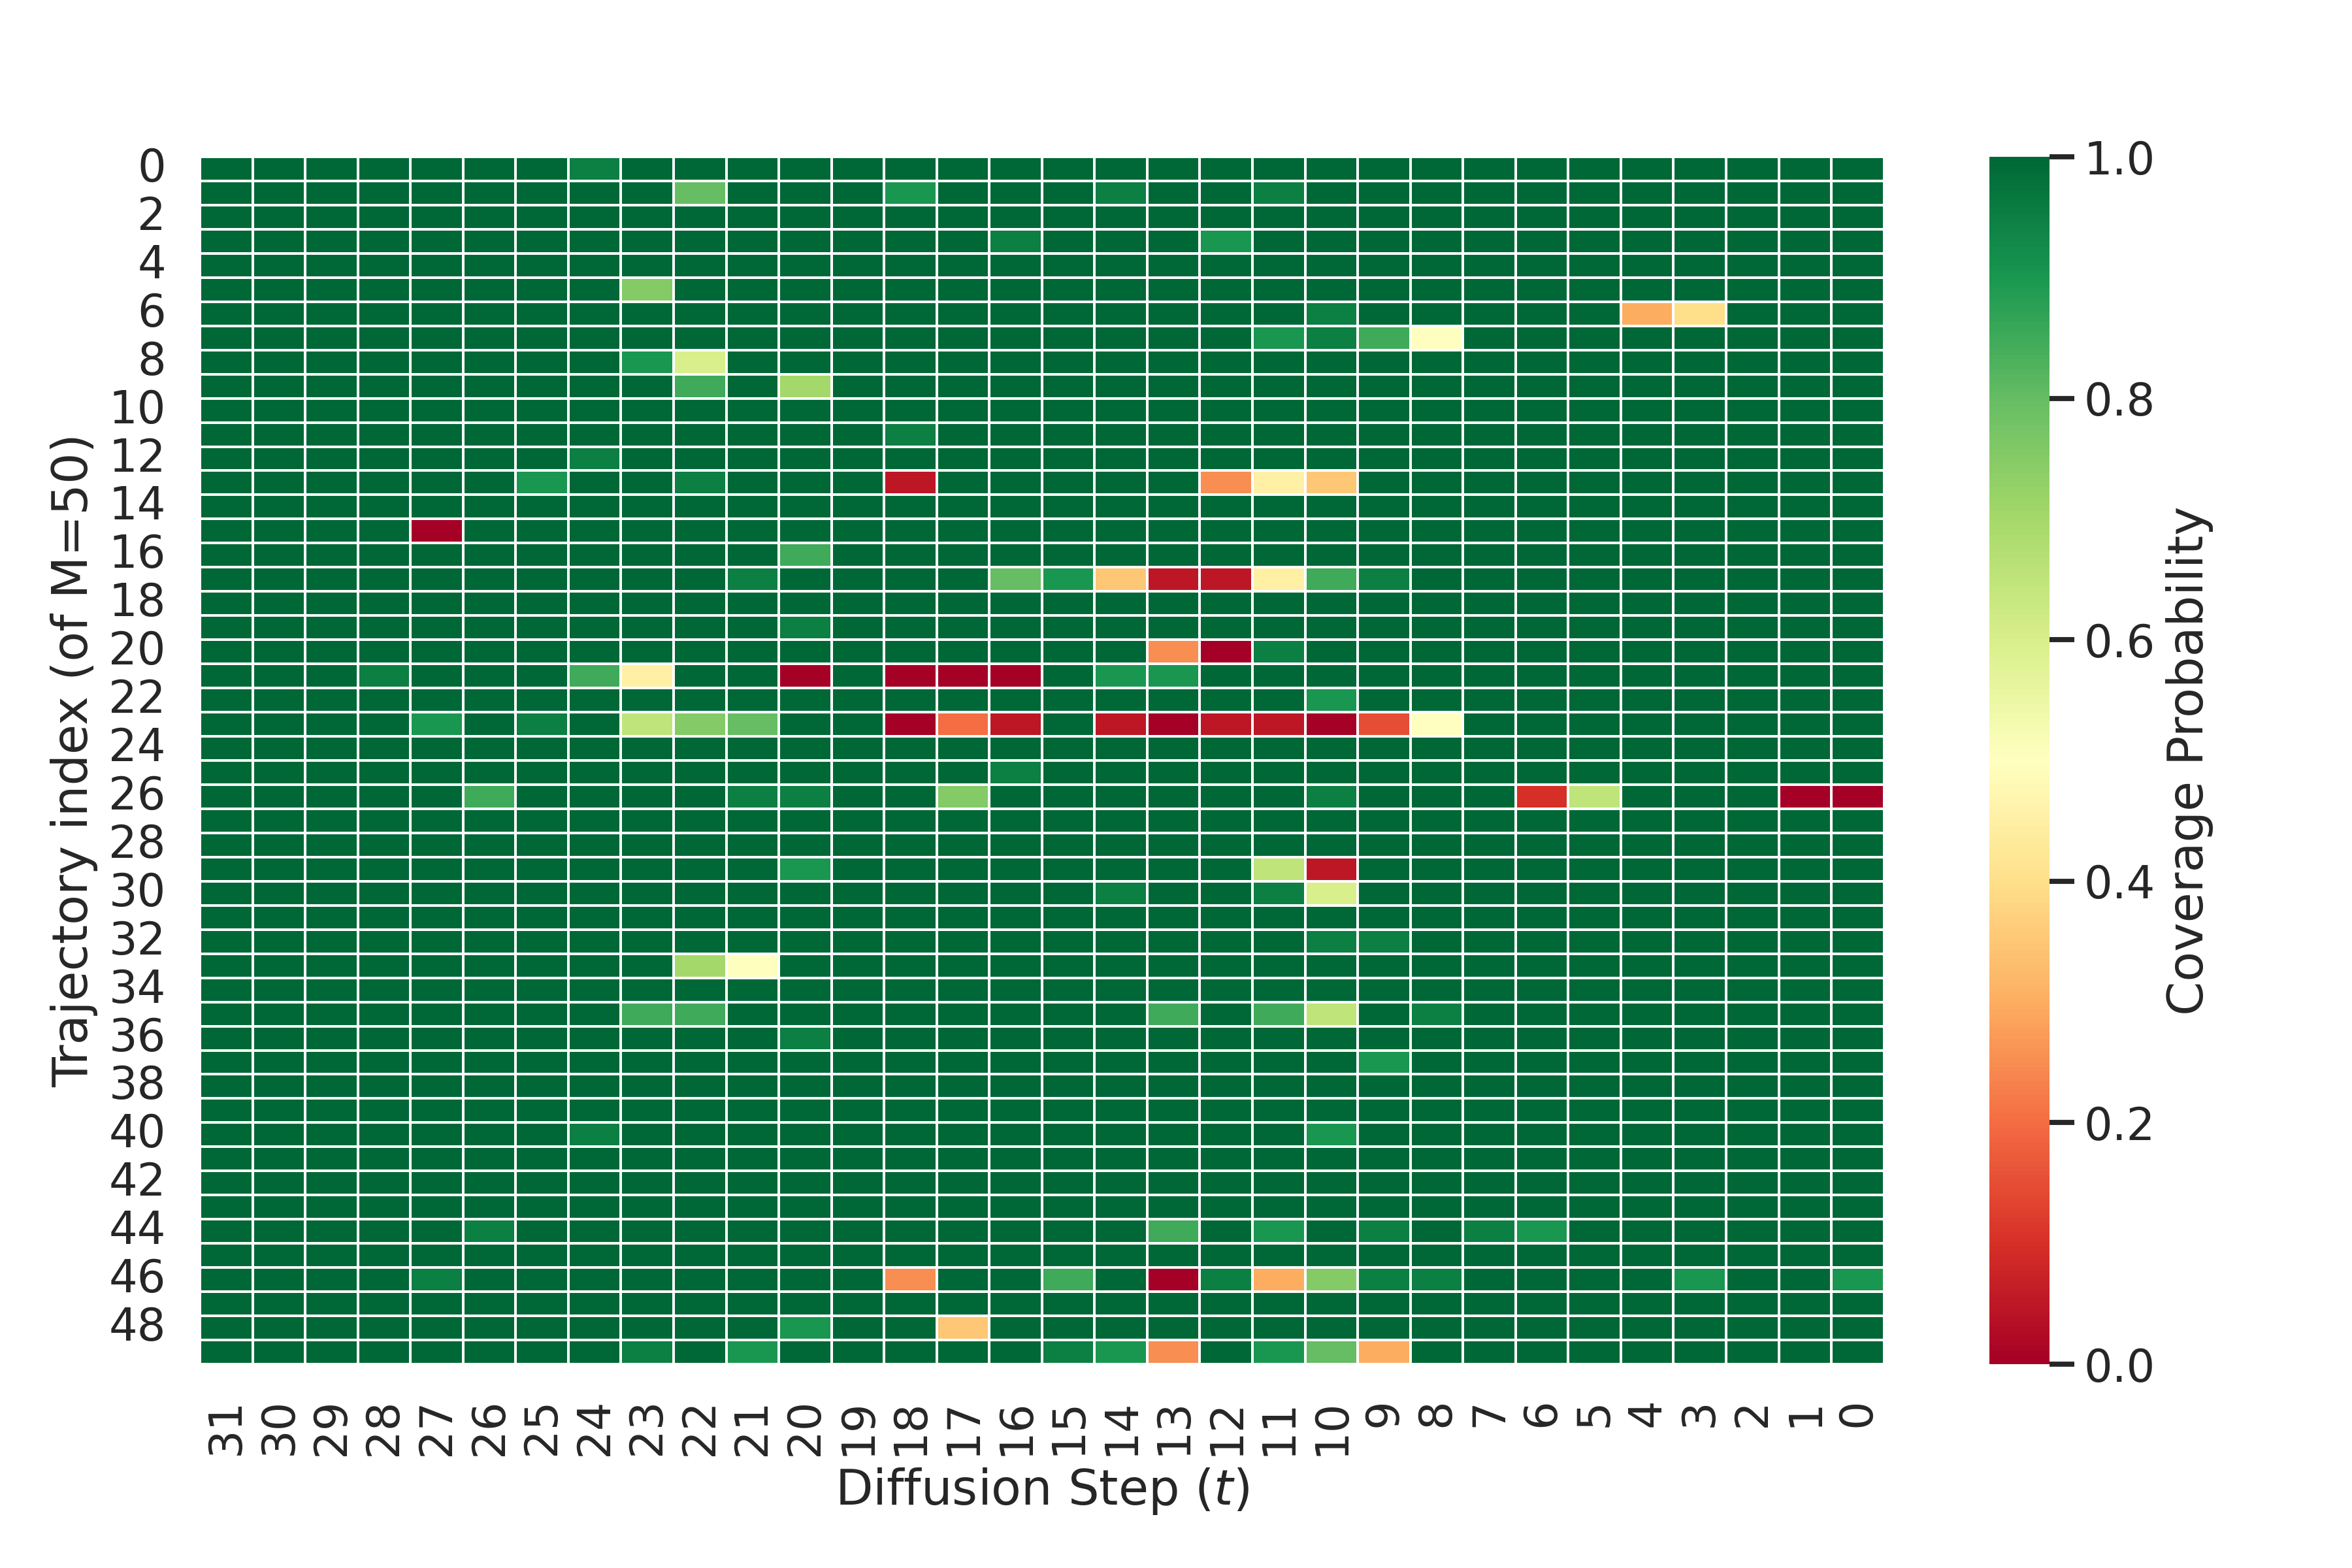

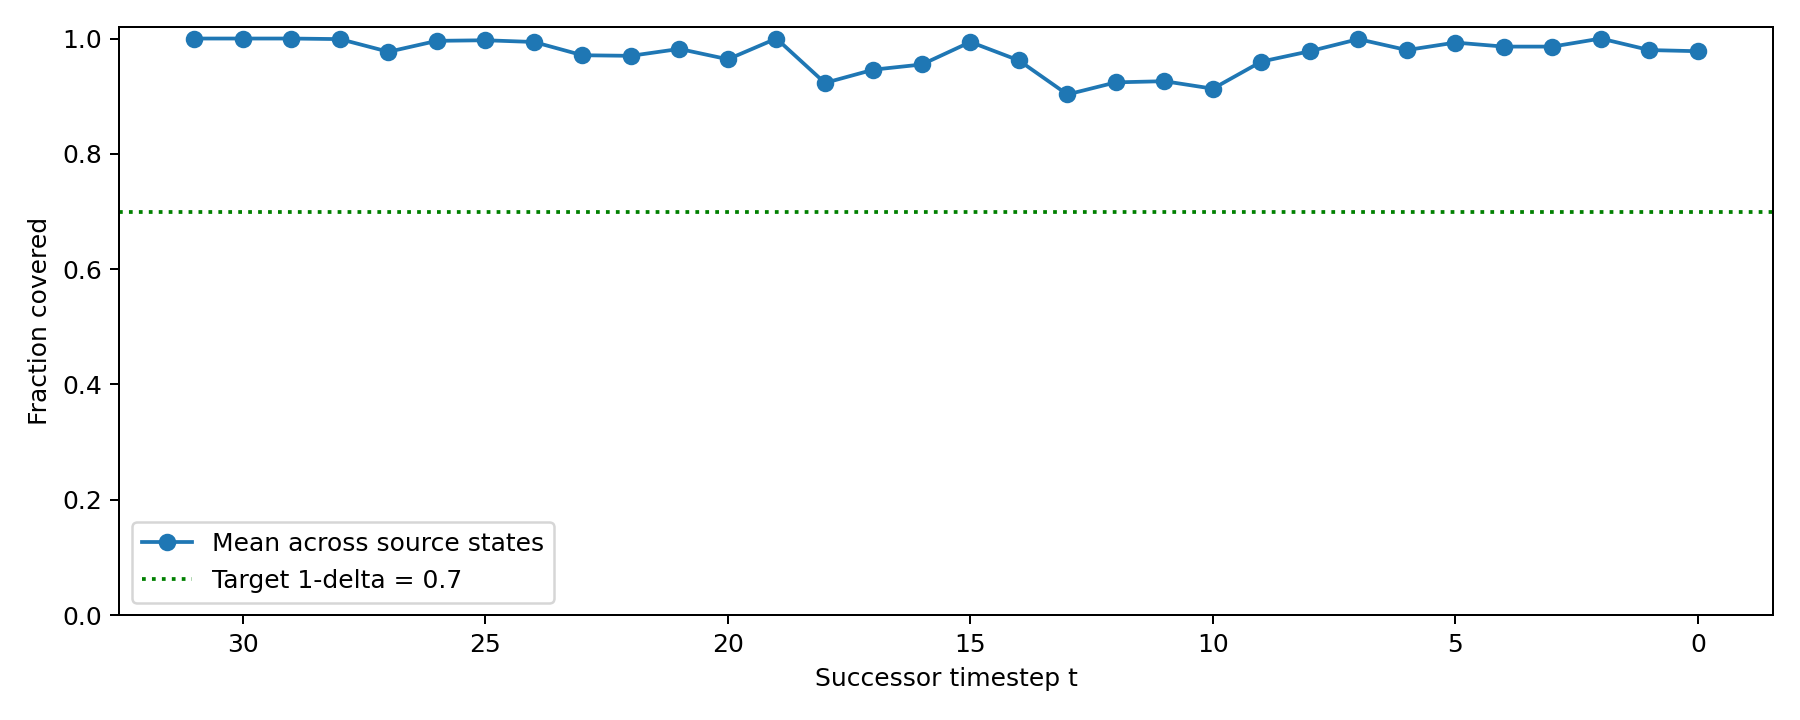

In [23]:
# Saved coverage results: alpha=0.3, delta=0.3.
import json
import numpy as np
from pathlib import Path
from IPython.display import Image, display

COV033_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p3_20261106_054849_004041')
summary033 = json.loads((COV033_DIR/'coverage_summary.json').read_text())
with np.load(COV033_DIR/'coverage.npz') as saved:
    covered033 = saved['covered']
    coverage033 = saved['coverage']
    assert np.array_equal(covered033, saved['log_values'] <= saved['thresholds'][:, :, None])
    assert np.array_equal(coverage033, covered033.mean(axis=2))
assert summary033['alpha'] == 0.3 and summary033['delta'] == 0.3
print(f"Coverage: {covered033.sum():,}/{covered033.size:,} ({100*covered033.mean():.4f}%)")
print(f"Target: {100*summary033['target_coverage']:.0f}%")
print(f"State–timestep pairs below target: {(coverage033 < summary033['target_coverage']).sum():,}/{coverage033.size:,}")
print(f"Minimum state–timestep coverage: {100*coverage033.min():.1f}%")
print('Saved in:', COV033_DIR)
display(Image(filename=str(COV033_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(COV033_DIR/'coverage_mean.png'), width=900))


In [24]:
# Coverage table at c=1/2: 10/20 proposals counts as passing.
import csv
import numpy as np
from pathlib import Path
from IPython.display import Markdown, display

COV033_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p3_20261106_054849_004041')
with np.load(COV033_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    source_steps = saved['source_steps']
    successor_steps = saved['successor_steps']

num_sources, num_probes = covered.shape[1:]
passing = (2 * covered.sum(axis=2) >= num_probes).sum(axis=1)
rows = [
    (int(s), int(t), int(n), num_sources, (num_sources-int(n))/num_sources)
    for s, t, n in zip(source_steps, successor_steps, passing)
]
csv_path = COV033_DIR/'coverage_zeta_c0p5.csv'
with csv_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_step', 'successor_step', 'passing_trajectories', 'num_trajectories', 'zeta'])
    writer.writerows(rows)

table = '| Transition | Trajectories with coverage ≥50% | ζ |\n|---|---:|---:|\n'
table += '\n'.join(f'| {s} → {t} | {n}/{total} | {zeta:.2f} |' for s, t, n, total, zeta in rows)
display(Markdown(table))
print(f'Worst-timestep zeta: {max(row[-1] for row in rows):.2f}')
print(f'Sum of zetas: {sum(row[-1] for row in rows):.2f}')
print('Saved:', csv_path)


| Transition | Trajectories with coverage ≥50% | ζ |
|---|---:|---:|
| 32 → 31 | 50/50 | 0.00 |
| 31 → 30 | 50/50 | 0.00 |
| 30 → 29 | 50/50 | 0.00 |
| 29 → 28 | 50/50 | 0.00 |
| 28 → 27 | 49/50 | 0.02 |
| 27 → 26 | 50/50 | 0.00 |
| 26 → 25 | 50/50 | 0.00 |
| 25 → 24 | 50/50 | 0.00 |
| 24 → 23 | 49/50 | 0.02 |
| 23 → 22 | 50/50 | 0.00 |
| 22 → 21 | 50/50 | 0.00 |
| 21 → 20 | 49/50 | 0.02 |
| 20 → 19 | 50/50 | 0.00 |
| 19 → 18 | 46/50 | 0.08 |
| 18 → 17 | 47/50 | 0.06 |
| 17 → 16 | 48/50 | 0.04 |
| 16 → 15 | 50/50 | 0.00 |
| 15 → 14 | 48/50 | 0.04 |
| 14 → 13 | 45/50 | 0.10 |
| 13 → 12 | 46/50 | 0.08 |
| 12 → 11 | 46/50 | 0.08 |
| 11 → 10 | 47/50 | 0.06 |
| 10 → 9 | 48/50 | 0.04 |
| 9 → 8 | 50/50 | 0.00 |
| 8 → 7 | 50/50 | 0.00 |
| 7 → 6 | 49/50 | 0.02 |
| 6 → 5 | 50/50 | 0.00 |
| 5 → 4 | 49/50 | 0.02 |
| 4 → 3 | 49/50 | 0.02 |
| 3 → 2 | 50/50 | 0.00 |
| 2 → 1 | 49/50 | 0.02 |
| 1 → 0 | 49/50 | 0.02 |

Worst-timestep zeta: 0.10
Sum of zetas: 0.74
Saved: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p3_20261106_054849_004041/coverage_zeta_c0p5.csv


In [25]:
# Coverage: alpha=0.5, delta=0.3.
from pathlib import Path
from datetime import datetime, timezone
import json, torch, shutil, subprocess, sys

ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
COV053_RUN = '20260205_195651_634076'
COV053_LCB = 'sweeps/lcb_lambda_only_SYM_post_trained_temp_0p5_del_0p3'
checkpoint_path = ROOT/'data_runs'/COV053_RUN/f'{COV053_LCB}.pt'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
training = json.loads(checkpoint_path.with_name(checkpoint_path.stem+'_results.json').read_text())
assert checkpoint['config']['delta'] == 0.3 and training['reward_temp'] == 0.5
print('Checkpoint:', checkpoint_path)
print('Alpha:', training['reward_temp'], 'Delta:', checkpoint['config']['delta'])
print('Calibrated transitions:', sum(bool(checkpoint['trained_t'][t]) and checkpoint['taus'][t] is not None for t in range(1,33)))
del checkpoint

COV053_DIR = ROOT/'reruns'/('coverage_a0p5_d0p3_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
print('Output:', COV053_DIR, flush=True)
!python -u "{ROOT}/analysis/coverage_experiment.py" --run_id {COV053_RUN} --lcb_name {COV053_LCB} --temp 0.5 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV053_DIR}"
assert (COV053_DIR/'coverage_summary.json').is_file()
(COV053_DIR/'command.txt').write_text(f'python -u analysis/coverage_experiment.py --run_id {COV053_RUN} --lcb_name {COV053_LCB} --temp 0.5 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV053_DIR}"\n')
(COV053_DIR/'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
shutil.copy2(ROOT/'analysis/coverage_experiment.py', COV053_DIR/'inference_script.py')


Checkpoint: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20260205_195651_634076/sweeps/lcb_lambda_only_SYM_post_trained_temp_0p5_del_0p3.pt
Alpha: 0.5 Delta: 0.3
Calibrated transitions: 32
Output: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p3_20261106_060623_784644
I0000 00:00:1793945189.896784   84018 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793945189.970891   84018 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793945192.537783   84018 port.cc:153] oneDNN custom operations are on. You may

PosixPath('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p3_20261106_060623_784644/inference_script.py')

Coverage: 31,217/32,000 (97.5531%)
Target: 70%
State–timestep pairs below target: 44/1,600
Minimum state–timestep coverage: 0.0%
Saved in: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p3_20261106_060623_784644


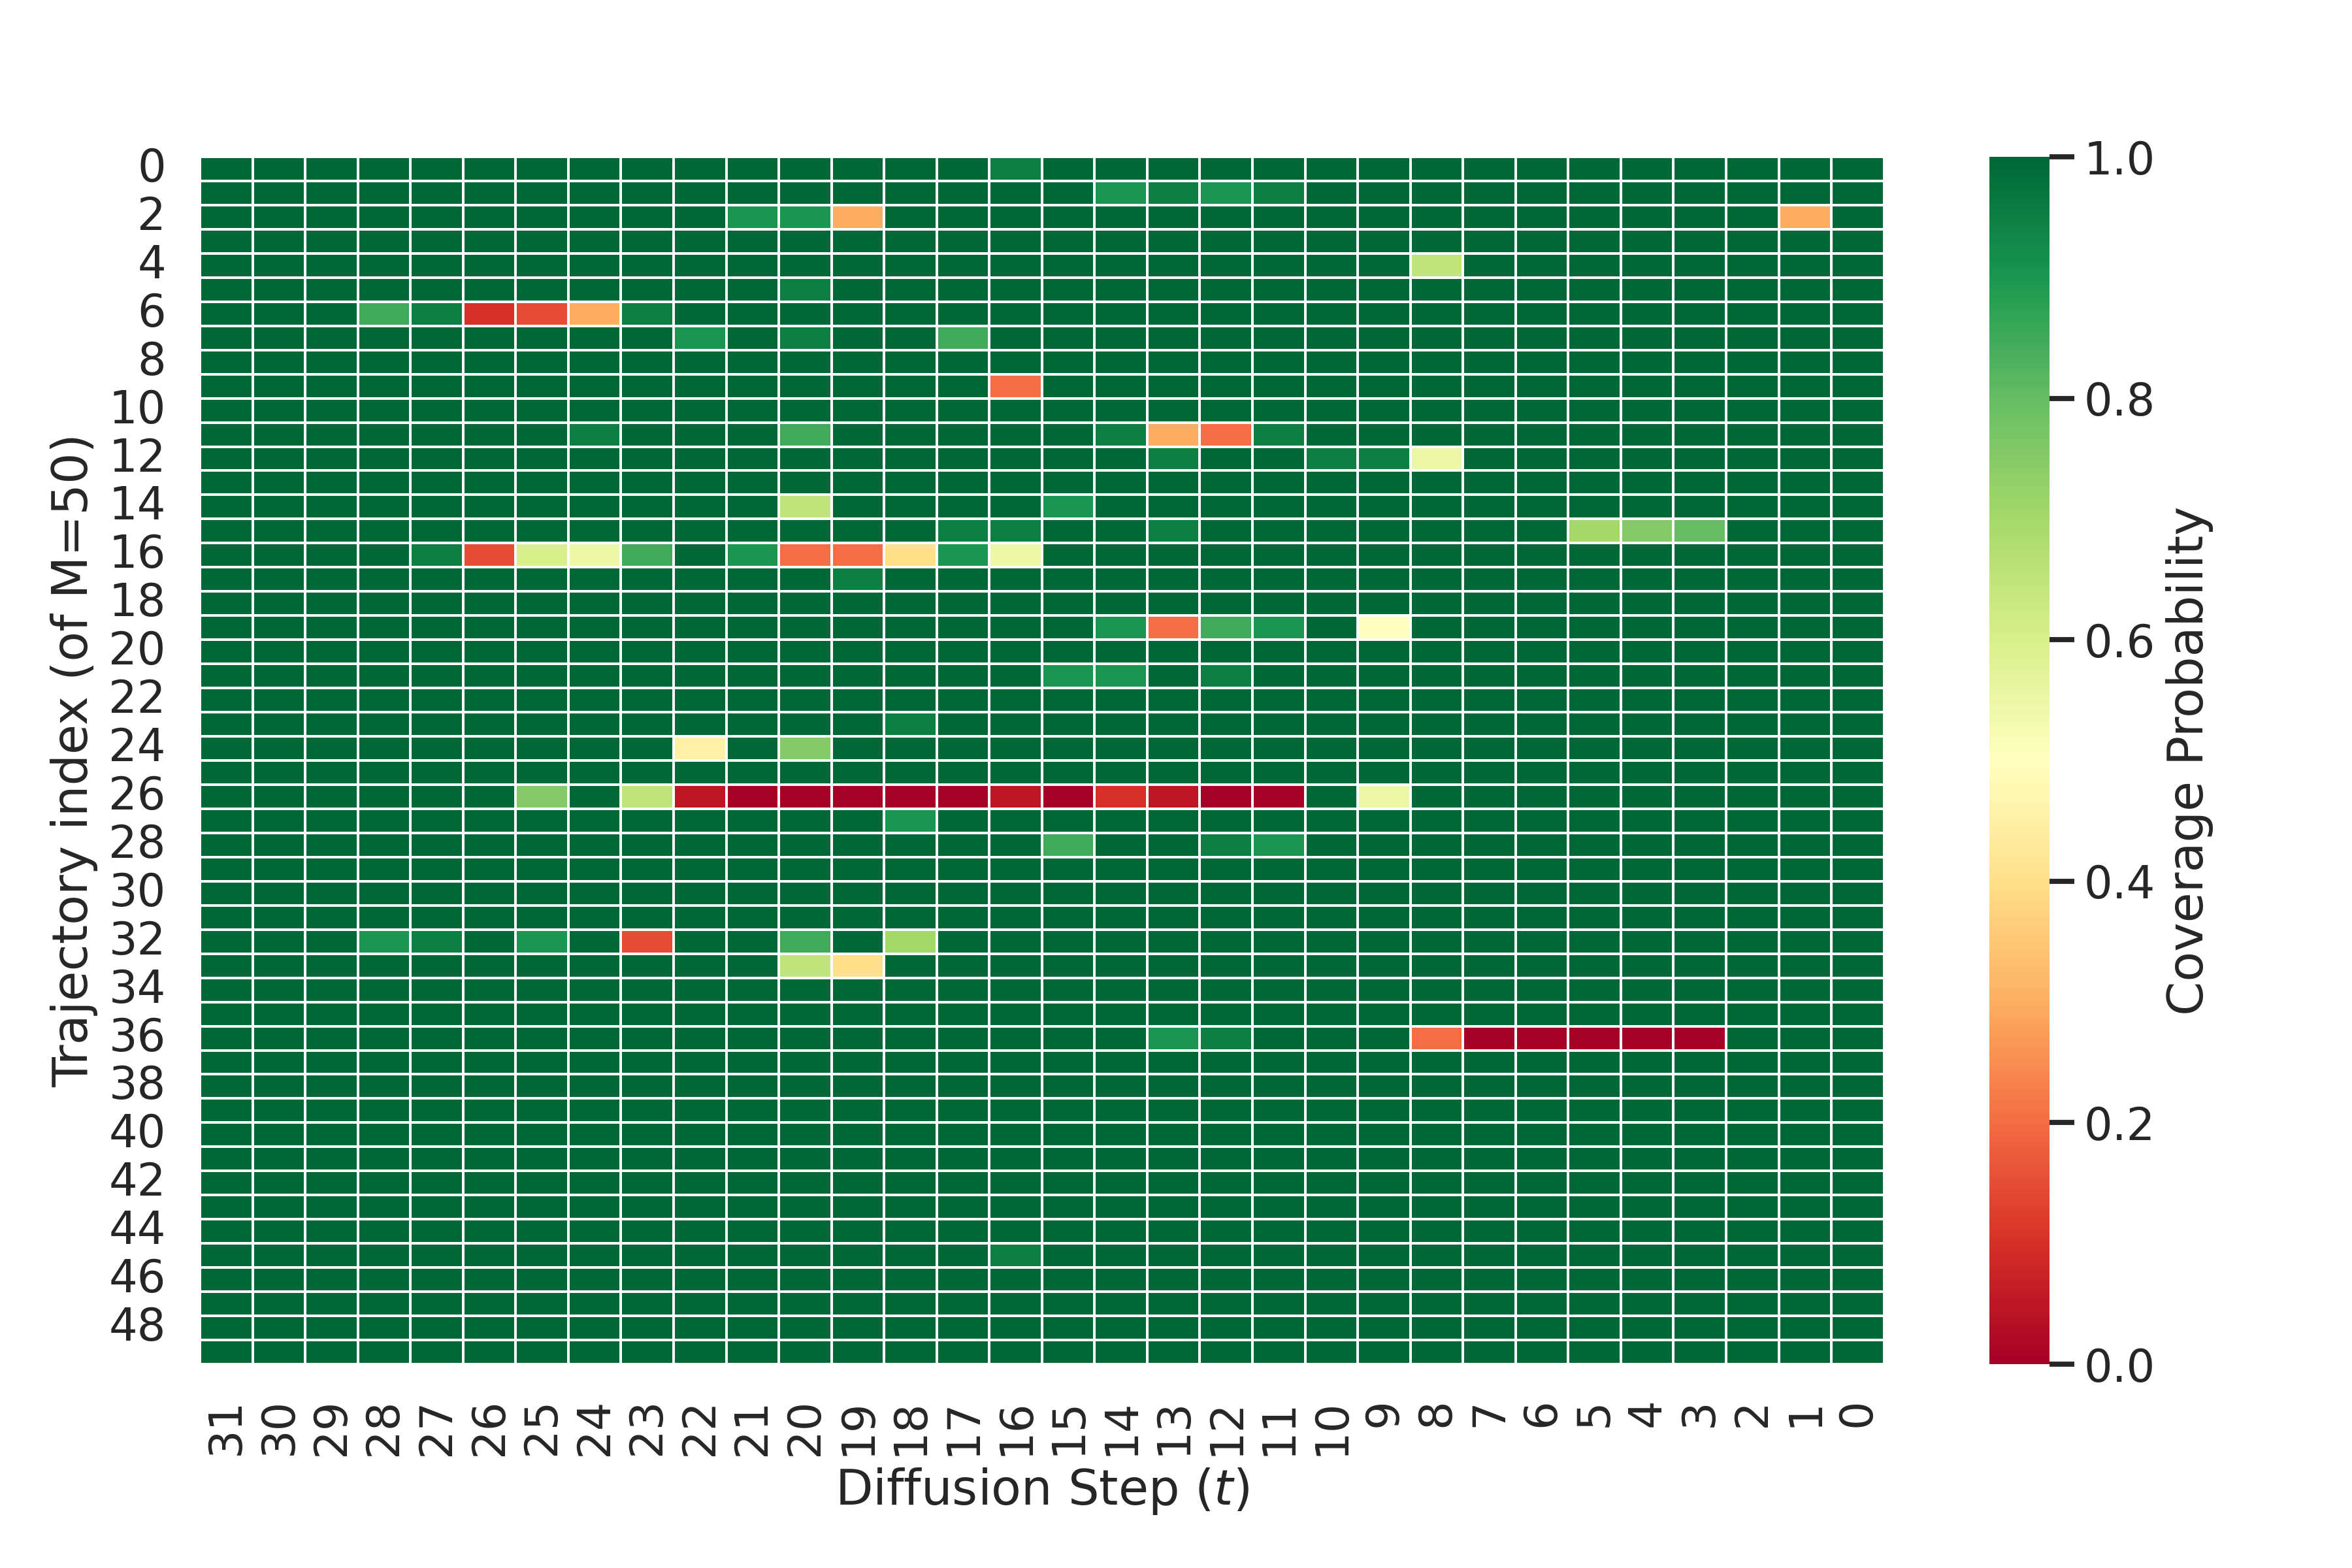

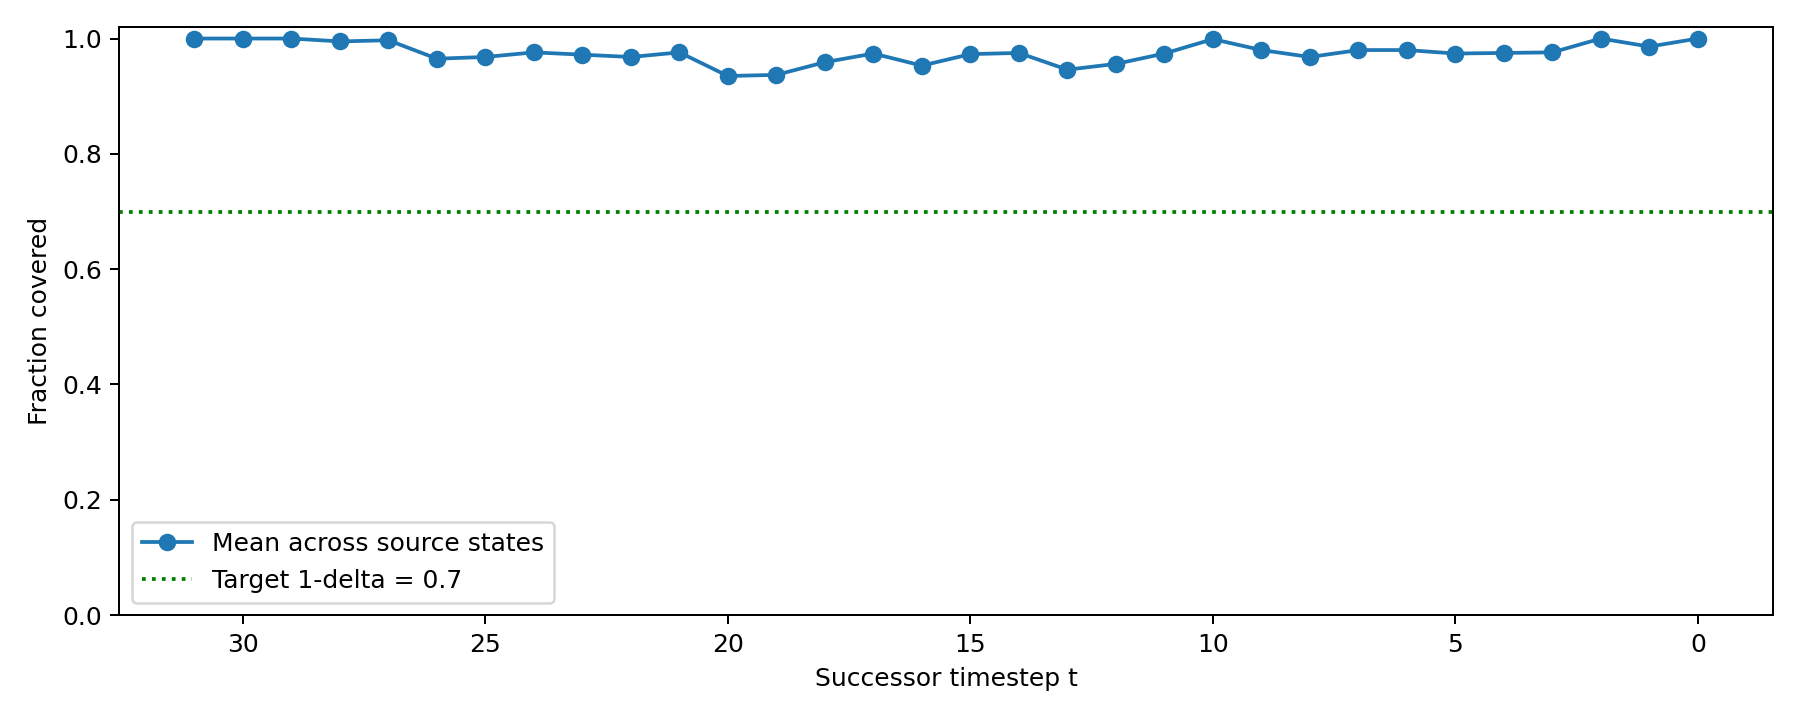

In [26]:
# Saved coverage results: alpha=0.5, delta=0.3.
import json
import numpy as np
from pathlib import Path
from IPython.display import Image, display

COV053_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p3_20261106_060623_784644')
summary053 = json.loads((COV053_DIR/'coverage_summary.json').read_text())
with np.load(COV053_DIR/'coverage.npz') as saved:
    covered053 = saved['covered']
    coverage053 = saved['coverage']
    assert np.array_equal(covered053, saved['log_values'] <= saved['thresholds'][:, :, None])
    assert np.array_equal(coverage053, covered053.mean(axis=2))
assert summary053['alpha'] == 0.5 and summary053['delta'] == 0.3
print(f"Coverage: {covered053.sum():,}/{covered053.size:,} ({100*covered053.mean():.4f}%)")
print(f"Target: {100*summary053['target_coverage']:.0f}%")
print(f"State–timestep pairs below target: {(coverage053 < summary053['target_coverage']).sum():,}/{coverage053.size:,}")
print(f"Minimum state–timestep coverage: {100*coverage053.min():.1f}%")
print('Saved in:', COV053_DIR)
display(Image(filename=str(COV053_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(COV053_DIR/'coverage_mean.png'), width=900))


In [27]:
# Coverage table at c=1/2: 10/20 proposals counts as passing.
import csv
import numpy as np
from pathlib import Path
from IPython.display import Markdown, display

COV053_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p3_20261106_060623_784644')
with np.load(COV053_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    source_steps = saved['source_steps']
    successor_steps = saved['successor_steps']

num_sources, num_probes = covered.shape[1:]
passing = (2 * covered.sum(axis=2) >= num_probes).sum(axis=1)
rows = [
    (int(s), int(t), int(n), num_sources, (num_sources-int(n))/num_sources)
    for s, t, n in zip(source_steps, successor_steps, passing)
]
csv_path = COV053_DIR/'coverage_zeta_c0p5.csv'
with csv_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_step', 'successor_step', 'passing_trajectories', 'num_trajectories', 'zeta'])
    writer.writerows(rows)

table = '| Transition | Trajectories with coverage ≥50% | ζ |\n|---|---:|---:|\n'
table += '\n'.join(f'| {s} → {t} | {n}/{total} | {zeta:.2f} |' for s, t, n, total, zeta in rows)
display(Markdown(table))
print(f'Worst-timestep zeta: {max(row[-1] for row in rows):.2f}')
print(f'Sum of zetas: {sum(row[-1] for row in rows):.2f}')
print(f'Cells below 50% coverage: {(num_sources-passing).sum()}/{passing.size*num_sources}')
print('Saved:', csv_path)


| Transition | Trajectories with coverage ≥50% | ζ |
|---|---:|---:|
| 32 → 31 | 50/50 | 0.00 |
| 31 → 30 | 50/50 | 0.00 |
| 30 → 29 | 50/50 | 0.00 |
| 29 → 28 | 50/50 | 0.00 |
| 28 → 27 | 50/50 | 0.00 |
| 27 → 26 | 48/50 | 0.04 |
| 26 → 25 | 49/50 | 0.02 |
| 25 → 24 | 49/50 | 0.02 |
| 24 → 23 | 49/50 | 0.02 |
| 23 → 22 | 48/50 | 0.04 |
| 22 → 21 | 49/50 | 0.02 |
| 21 → 20 | 48/50 | 0.04 |
| 20 → 19 | 46/50 | 0.08 |
| 19 → 18 | 48/50 | 0.04 |
| 18 → 17 | 49/50 | 0.02 |
| 17 → 16 | 48/50 | 0.04 |
| 16 → 15 | 49/50 | 0.02 |
| 15 → 14 | 49/50 | 0.02 |
| 14 → 13 | 47/50 | 0.06 |
| 13 → 12 | 48/50 | 0.04 |
| 12 → 11 | 49/50 | 0.02 |
| 11 → 10 | 50/50 | 0.00 |
| 10 → 9 | 50/50 | 0.00 |
| 9 → 8 | 49/50 | 0.02 |
| 8 → 7 | 49/50 | 0.02 |
| 7 → 6 | 49/50 | 0.02 |
| 6 → 5 | 49/50 | 0.02 |
| 5 → 4 | 49/50 | 0.02 |
| 4 → 3 | 49/50 | 0.02 |
| 3 → 2 | 50/50 | 0.00 |
| 2 → 1 | 49/50 | 0.02 |
| 1 → 0 | 50/50 | 0.00 |

Worst-timestep zeta: 0.08
Sum of zetas: 0.68
Cells below 50% coverage: 34/1600
Saved: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p5_d0p3_20261106_060623_784644/coverage_zeta_c0p5.csv


In [31]:
# Coverage: alpha=0.3, delta=0.1.
from pathlib import Path
from datetime import datetime, timezone
import json, torch, shutil, subprocess, sys

ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
COV031_RUN = '20251224_233551_699407'
COV031_LCB = 'lcb_lambda_only_max_6_post_trained_temp_0p3'
checkpoint_path = ROOT/'data_runs'/COV031_RUN/f'{COV031_LCB}.pt'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
training = json.loads(checkpoint_path.with_name(checkpoint_path.stem+'_results.json').read_text())
assert checkpoint['config']['delta'] == 0.1 and training['reward_temp'] == 0.3
print('Checkpoint:', checkpoint_path)
print('Alpha:', training['reward_temp'], 'Delta:', checkpoint['config']['delta'])
del checkpoint

COV031_DIR = ROOT/'reruns'/('coverage_a0p3_d0p1_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
print('Output:', COV031_DIR, flush=True)
!python -u "{ROOT}/analysis/coverage_experiment.py" --run_id {COV031_RUN} --lcb_name {COV031_LCB} --temp 0.3 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV031_DIR}"
assert (COV031_DIR/'coverage_summary.json').is_file()
(COV031_DIR/'command.txt').write_text(f'python -u analysis/coverage_experiment.py --run_id {COV031_RUN} --lcb_name {COV031_LCB} --temp 0.3 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV031_DIR}"\n')
(COV031_DIR/'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
shutil.copy2(ROOT/'analysis/coverage_experiment.py', COV031_DIR/'inference_script.py')


Checkpoint: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20251224_233551_699407/lcb_lambda_only_max_6_post_trained_temp_0p3.pt
Alpha: 0.3 Delta: 0.1
Output: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p1_20261106_205000_877595
I0000 00:00:1793998206.660742  302239 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793998206.731146  302239 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793998209.205493  302239 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical result

PosixPath('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p1_20261106_205000_877595/inference_script.py')

Coverage: 31,861/32,000 (99.5656%)
Target: 90%
State–timestep pairs below target: 10/1,600
Minimum state–timestep coverage: 0.0%
Saved in: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p1_20261106_205000_877595


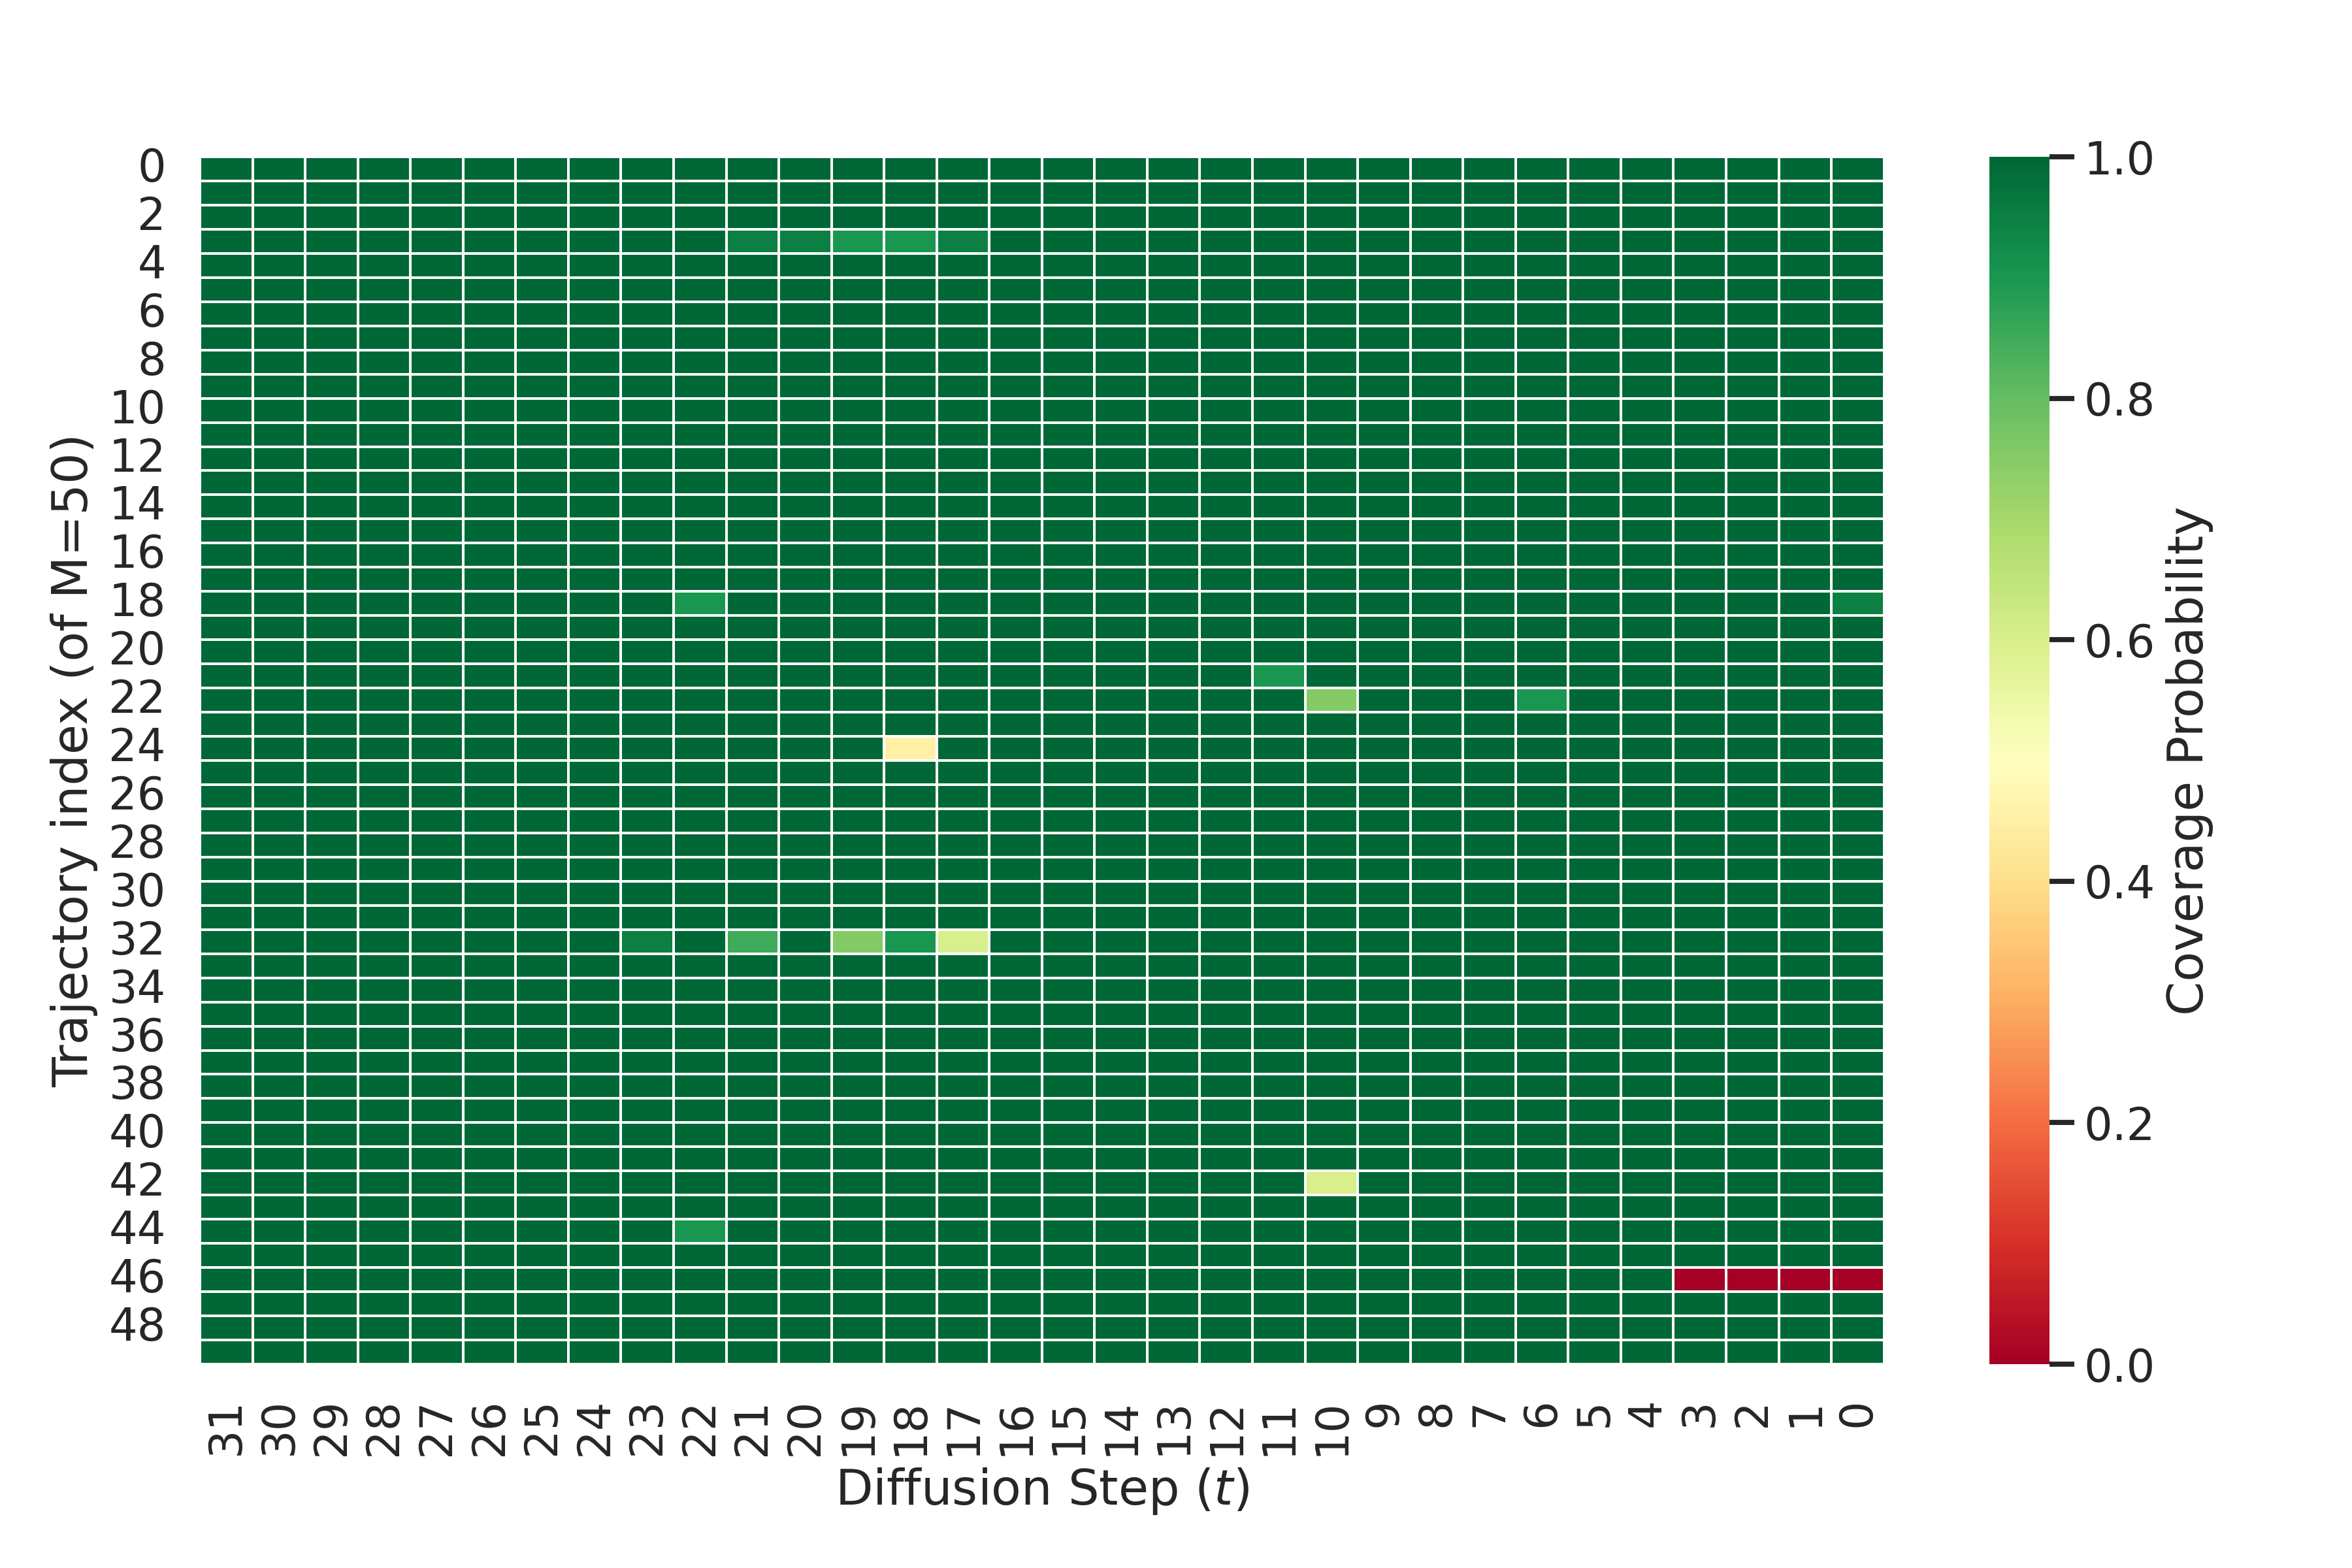

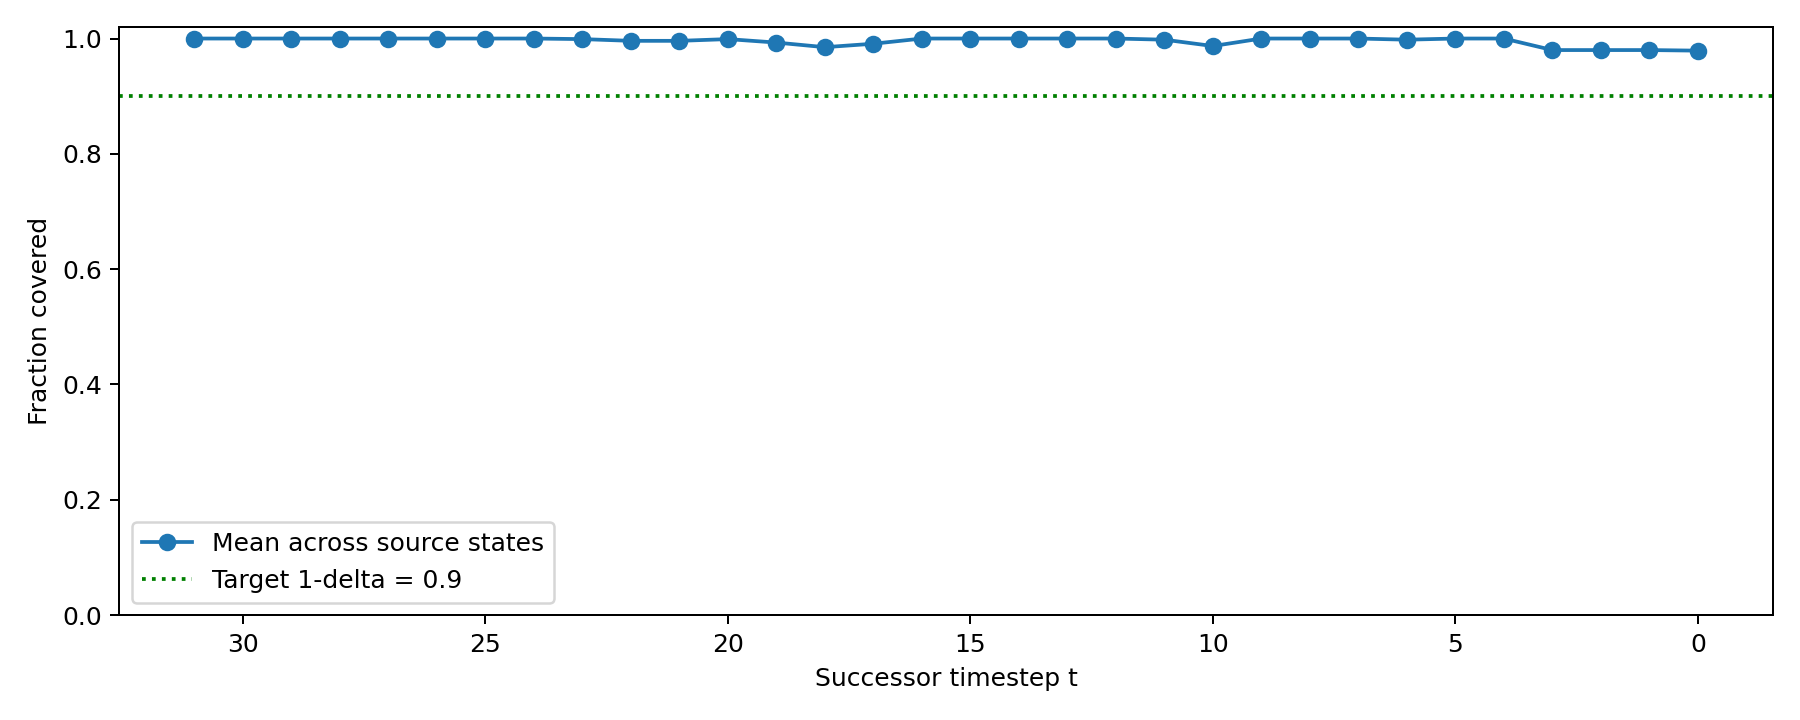

In [32]:
# Saved coverage results: alpha=0.3, delta=0.1.
import json
import numpy as np
from pathlib import Path
from IPython.display import Image, display

COV031_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p1_20261106_205000_877595')
summary031 = json.loads((COV031_DIR/'coverage_summary.json').read_text())
with np.load(COV031_DIR/'coverage.npz') as saved:
    covered031 = saved['covered']
    coverage031 = saved['coverage']
    assert np.array_equal(covered031, saved['log_values'] <= saved['thresholds'][:, :, None])
    assert np.array_equal(coverage031, covered031.mean(axis=2))
assert summary031['alpha'] == 0.3 and summary031['delta'] == 0.1
print(f"Coverage: {covered031.sum():,}/{covered031.size:,} ({100*covered031.mean():.4f}%)")
print(f"Target: {100*summary031['target_coverage']:.0f}%")
print(f"State–timestep pairs below target: {(coverage031 < summary031['target_coverage']).sum():,}/{coverage031.size:,}")
print(f"Minimum state–timestep coverage: {100*coverage031.min():.1f}%")
print('Saved in:', COV031_DIR)
display(Image(filename=str(COV031_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(COV031_DIR/'coverage_mean.png'), width=900))


In [33]:
# Coverage table at c=1/2: 10/20 proposals counts as passing.
import csv
import numpy as np
from pathlib import Path
from IPython.display import Markdown, display

COV031_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p1_20261106_205000_877595')
with np.load(COV031_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    source_steps = saved['source_steps']
    successor_steps = saved['successor_steps']

num_sources, num_probes = covered.shape[1:]
passing = (2 * covered.sum(axis=2) >= num_probes).sum(axis=1)
rows = [
    (int(s), int(t), int(n), num_sources, (num_sources-int(n))/num_sources)
    for s, t, n in zip(source_steps, successor_steps, passing)
]
csv_path = COV031_DIR/'coverage_zeta_c0p5.csv'
with csv_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_step', 'successor_step', 'passing_trajectories', 'num_trajectories', 'zeta'])
    writer.writerows(rows)

table = '| Transition | Trajectories with coverage ≥50% | ζ |\n|---|---:|---:|\n'
table += '\n'.join(f'| {s} → {t} | {n}/{total} | {zeta:.2f} |' for s, t, n, total, zeta in rows)
display(Markdown(table))
print(f'Worst-timestep zeta: {max(row[-1] for row in rows):.2f}')
print(f'Sum of zetas: {sum(row[-1] for row in rows):.2f}')
print(f'Cells below 50% coverage: {(num_sources-passing).sum()}/{passing.size*num_sources}')
print('Saved:', csv_path)


| Transition | Trajectories with coverage ≥50% | ζ |
|---|---:|---:|
| 32 → 31 | 50/50 | 0.00 |
| 31 → 30 | 50/50 | 0.00 |
| 30 → 29 | 50/50 | 0.00 |
| 29 → 28 | 50/50 | 0.00 |
| 28 → 27 | 50/50 | 0.00 |
| 27 → 26 | 50/50 | 0.00 |
| 26 → 25 | 50/50 | 0.00 |
| 25 → 24 | 50/50 | 0.00 |
| 24 → 23 | 50/50 | 0.00 |
| 23 → 22 | 50/50 | 0.00 |
| 22 → 21 | 50/50 | 0.00 |
| 21 → 20 | 50/50 | 0.00 |
| 20 → 19 | 50/50 | 0.00 |
| 19 → 18 | 49/50 | 0.02 |
| 18 → 17 | 50/50 | 0.00 |
| 17 → 16 | 50/50 | 0.00 |
| 16 → 15 | 50/50 | 0.00 |
| 15 → 14 | 50/50 | 0.00 |
| 14 → 13 | 50/50 | 0.00 |
| 13 → 12 | 50/50 | 0.00 |
| 12 → 11 | 50/50 | 0.00 |
| 11 → 10 | 50/50 | 0.00 |
| 10 → 9 | 50/50 | 0.00 |
| 9 → 8 | 50/50 | 0.00 |
| 8 → 7 | 50/50 | 0.00 |
| 7 → 6 | 50/50 | 0.00 |
| 6 → 5 | 50/50 | 0.00 |
| 5 → 4 | 50/50 | 0.00 |
| 4 → 3 | 49/50 | 0.02 |
| 3 → 2 | 49/50 | 0.02 |
| 2 → 1 | 49/50 | 0.02 |
| 1 → 0 | 49/50 | 0.02 |

Worst-timestep zeta: 0.02
Sum of zetas: 0.10
Cells below 50% coverage: 5/1600
Saved: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p3_d0p1_20261106_205000_877595/coverage_zeta_c0p5.csv


In [34]:
# Coverage: alpha=0.1, delta=0.1.
from pathlib import Path
from datetime import datetime, timezone
import json, torch, shutil, subprocess, sys

ROOT = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward')
COV011_RUN = '20251224_233551_699407'
COV011_LCB = 'lcb_lambda_only_SYM_post_trained_temp_0p1'
checkpoint_path = ROOT/'data_runs'/COV011_RUN/f'{COV011_LCB}.pt'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
training = json.loads(checkpoint_path.with_name(checkpoint_path.stem+'_results.json').read_text())
assert checkpoint['config']['delta'] == 0.1 and training['reward_temp'] == 0.1
print('Checkpoint:', checkpoint_path)
print('Alpha:', training['reward_temp'], 'Delta:', checkpoint['config']['delta'])
del checkpoint

COV011_DIR = ROOT/'reruns'/('coverage_a0p1_d0p1_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
print('Output:', COV011_DIR, flush=True)
!python -u "{ROOT}/analysis/coverage_experiment.py" --run_id {COV011_RUN} --lcb_name {COV011_LCB} --temp 0.1 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV011_DIR}"
assert (COV011_DIR/'coverage_summary.json').is_file()
(COV011_DIR/'command.txt').write_text(f'python -u analysis/coverage_experiment.py --run_id {COV011_RUN} --lcb_name {COV011_LCB} --temp 0.1 --num_samples 50 --num_probes 20 --seed 42 --output_dir "{COV011_DIR}"\n')
(COV011_DIR/'environment.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
shutil.copy2(ROOT/'analysis/coverage_experiment.py', COV011_DIR/'inference_script.py')


Checkpoint: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/data_runs/20251224_233551_699407/lcb_lambda_only_SYM_post_trained_temp_0p1.pt
Alpha: 0.1 Delta: 0.1
Output: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p1_d0p1_20261106_205508_037412
I0000 00:00:1793998514.115833  303670 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793998514.185181  303670 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793998516.682218  303670 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results 

PosixPath('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p1_d0p1_20261106_205508_037412/inference_script.py')

Coverage: 31,762/32,000 (99.2562%)
Target: 90%
State–timestep pairs below target: 14/1,600
Minimum state–timestep coverage: 0.0%
Saved in: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p1_d0p1_20261106_205508_037412


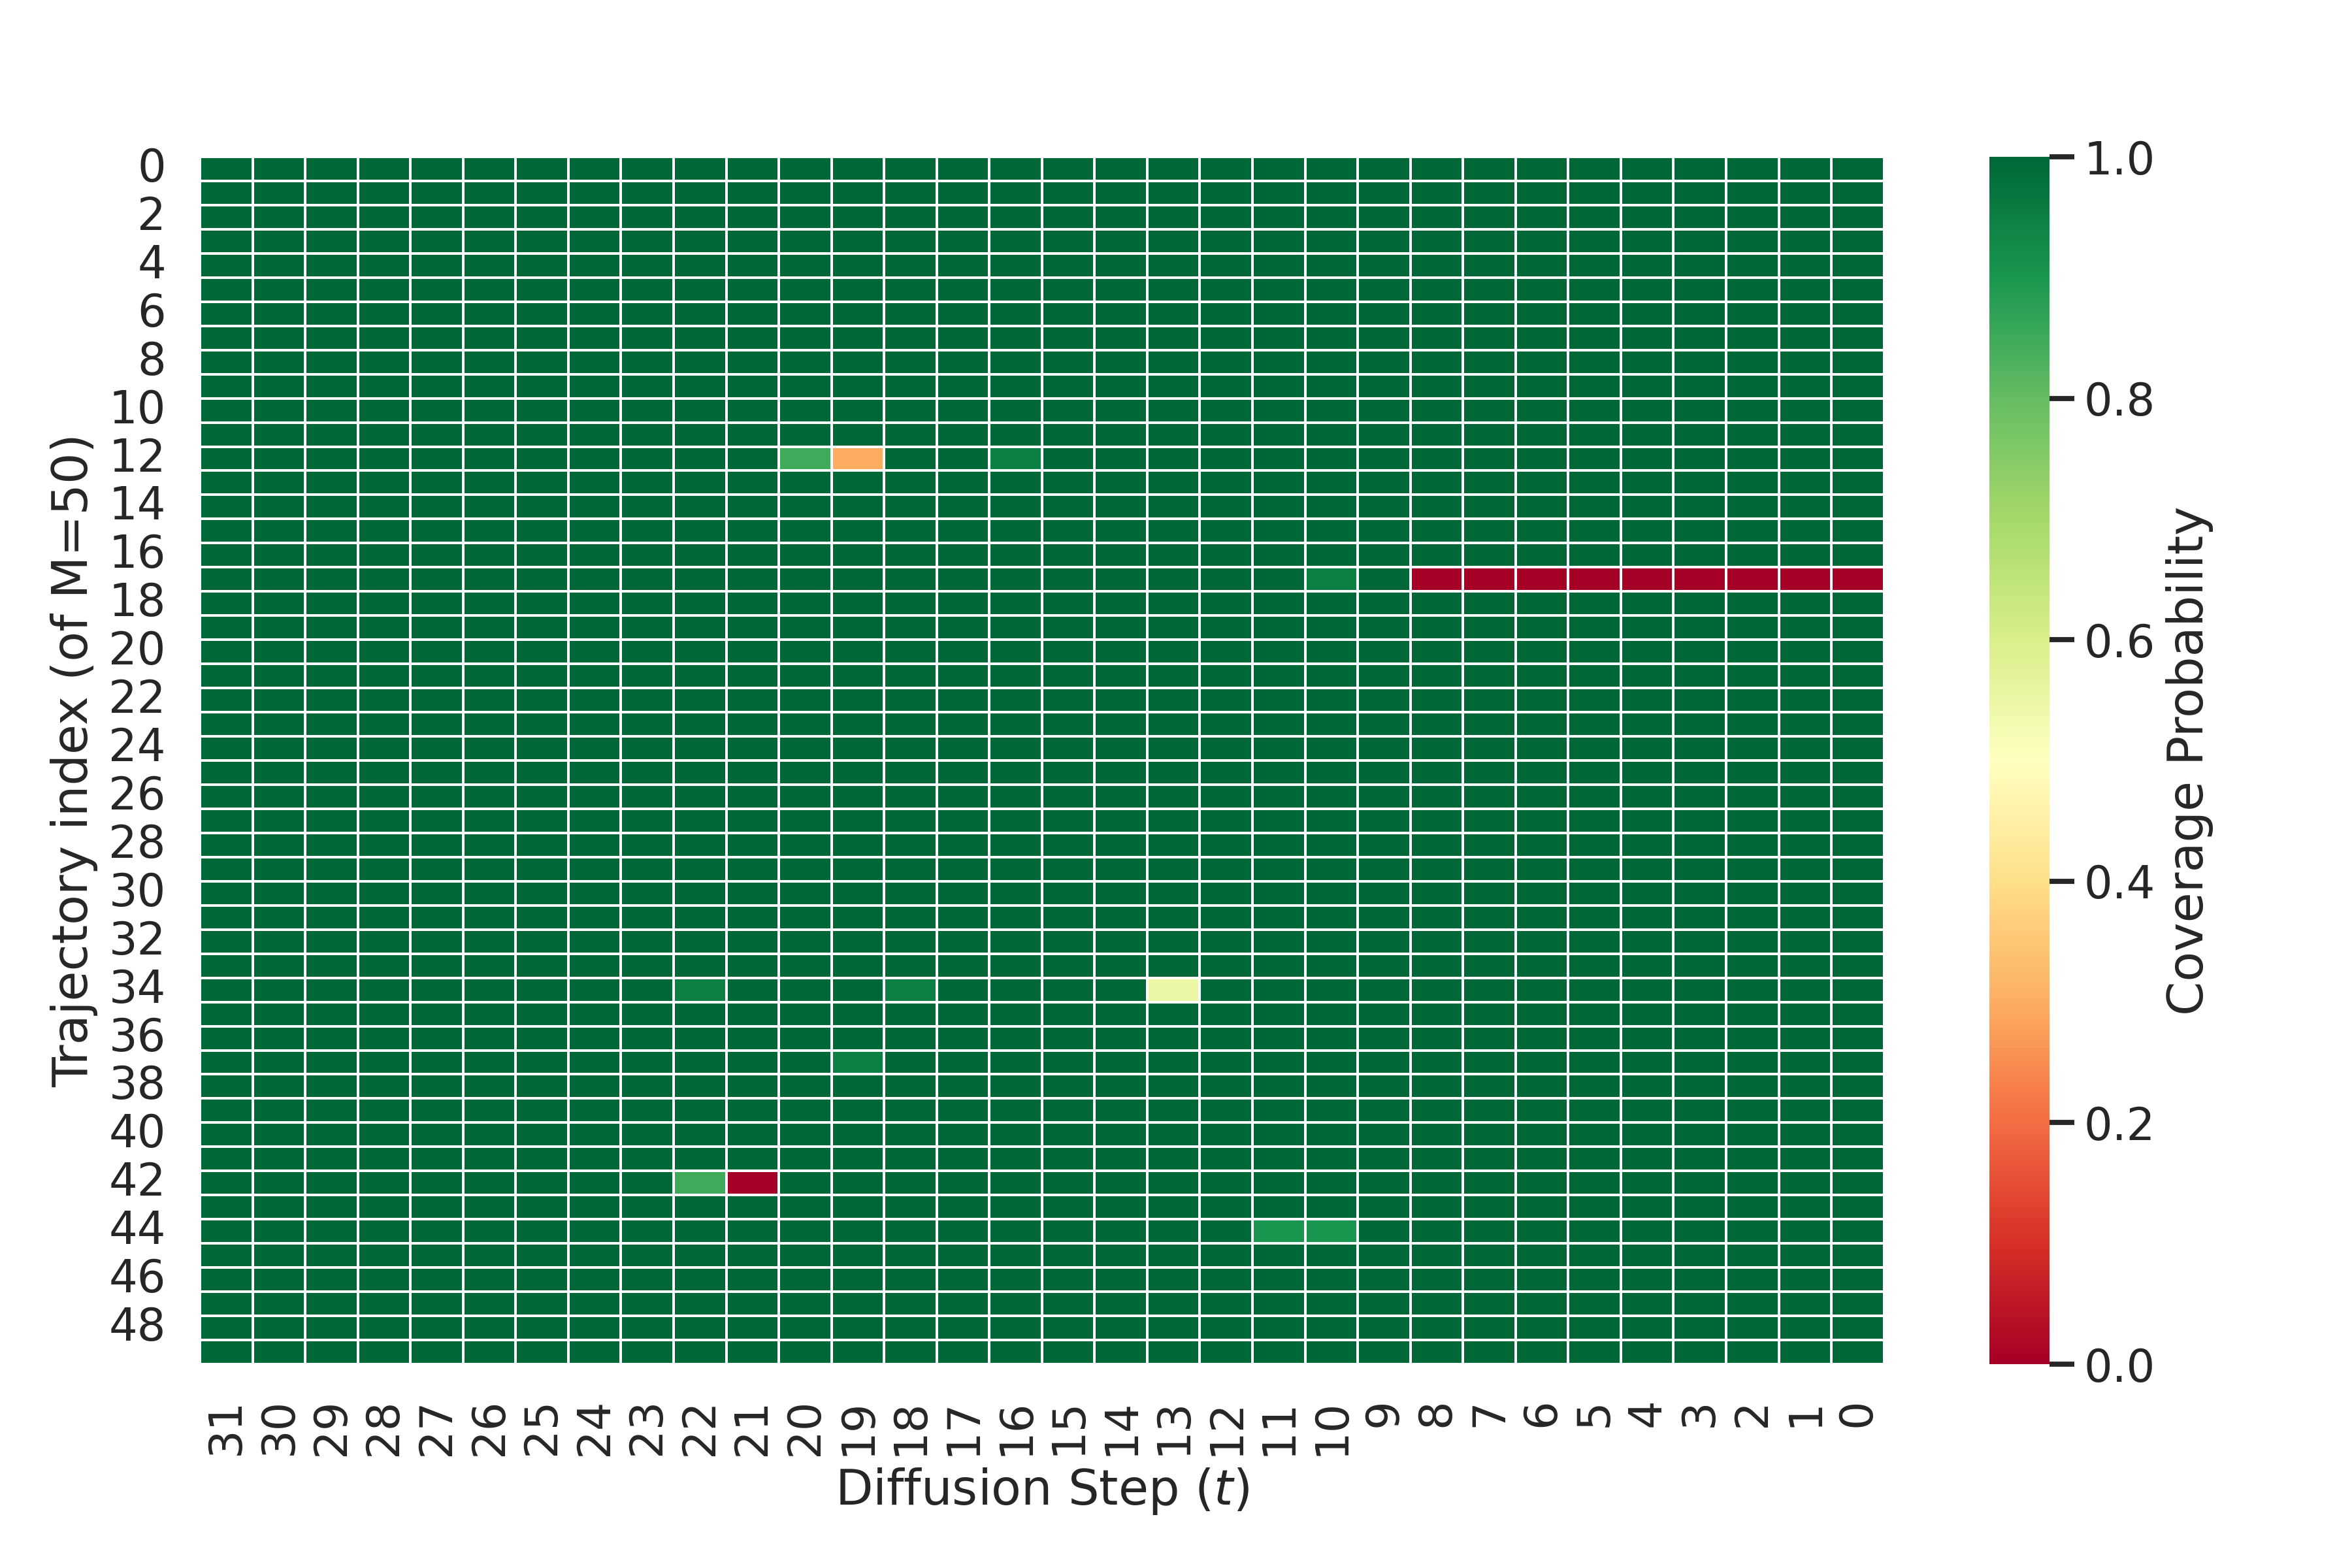

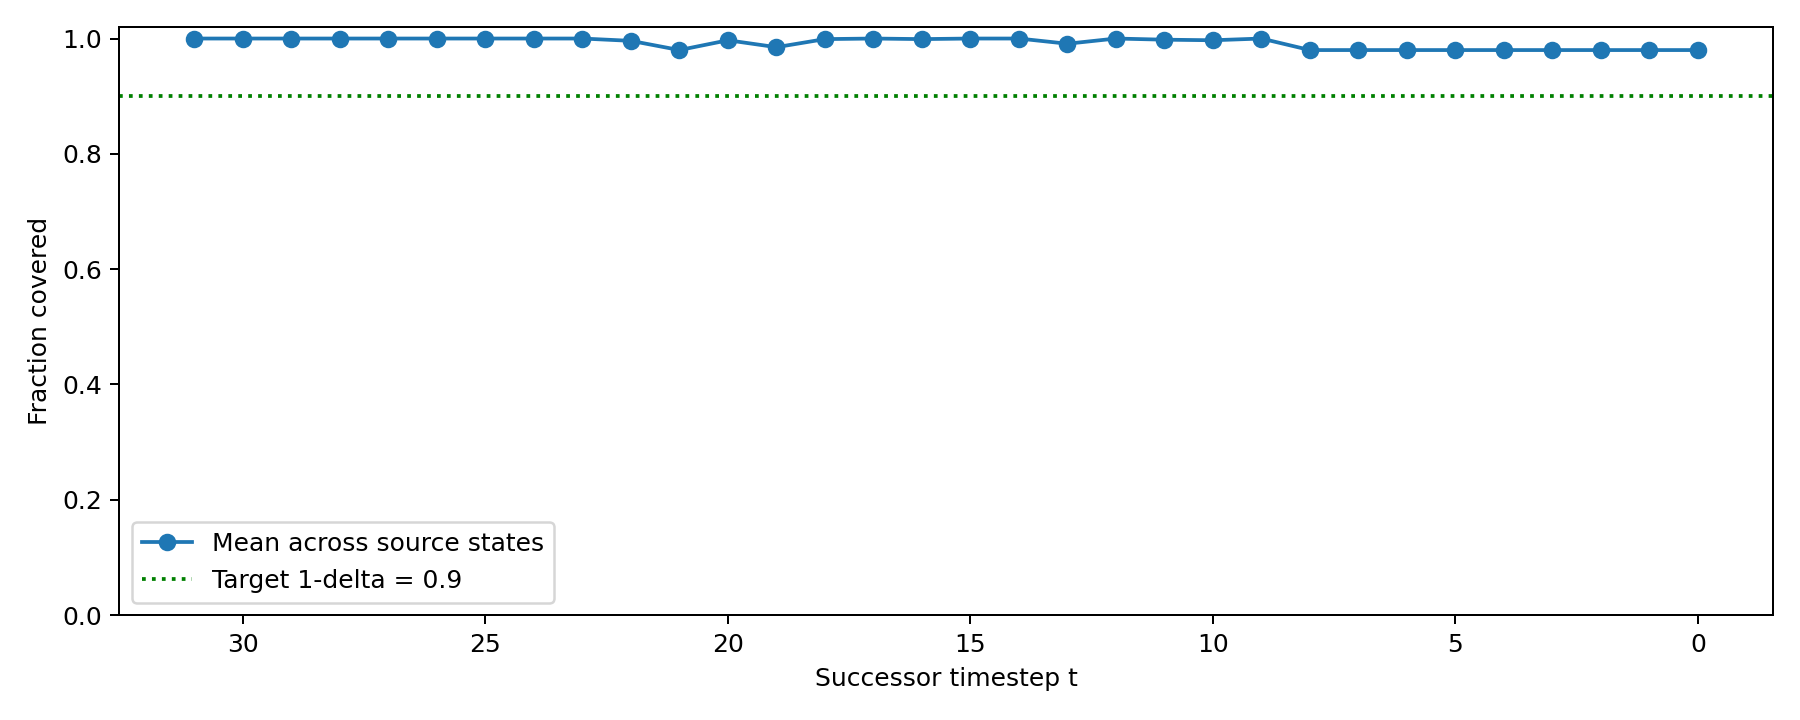

In [35]:
# Saved coverage results: alpha=0.1, delta=0.1.
import json
import numpy as np
from pathlib import Path
from IPython.display import Image, display

COV011_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p1_d0p1_20261106_205508_037412')
summary011 = json.loads((COV011_DIR/'coverage_summary.json').read_text())
with np.load(COV011_DIR/'coverage.npz') as saved:
    covered011 = saved['covered']
    coverage011 = saved['coverage']
    assert np.array_equal(covered011, saved['log_values'] <= saved['thresholds'][:, :, None])
    assert np.array_equal(coverage011, covered011.mean(axis=2))
assert summary011['alpha'] == 0.1 and summary011['delta'] == 0.1
print(f"Coverage: {covered011.sum():,}/{covered011.size:,} ({100*covered011.mean():.4f}%)")
print(f"Target: {100*summary011['target_coverage']:.0f}%")
print(f"State–timestep pairs below target: {(coverage011 < summary011['target_coverage']).sum():,}/{coverage011.size:,}")
print(f"Minimum state–timestep coverage: {100*coverage011.min():.1f}%")
print('Saved in:', COV011_DIR)
display(Image(filename=str(COV011_DIR/'coverage_heatmap.png'), width=900))
display(Image(filename=str(COV011_DIR/'coverage_mean.png'), width=900))


In [36]:
# Coverage table at c=1/2: 10/20 proposals counts as passing.
import csv
import numpy as np
from pathlib import Path
from IPython.display import Markdown, display

COV011_DIR = Path('/content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p1_d0p1_20261106_205508_037412')
with np.load(COV011_DIR/'coverage.npz') as saved:
    covered = saved['covered']
    source_steps = saved['source_steps']
    successor_steps = saved['successor_steps']

num_sources, num_probes = covered.shape[1:]
passing = (2 * covered.sum(axis=2) >= num_probes).sum(axis=1)
rows = [
    (int(s), int(t), int(n), num_sources, (num_sources-int(n))/num_sources)
    for s, t, n in zip(source_steps, successor_steps, passing)
]
csv_path = COV011_DIR/'coverage_zeta_c0p5.csv'
with csv_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_step', 'successor_step', 'passing_trajectories', 'num_trajectories', 'zeta'])
    writer.writerows(rows)

table = '| Transition | Trajectories with coverage ≥50% | ζ |\n|---|---:|---:|\n'
table += '\n'.join(f'| {s} → {t} | {n}/{total} | {zeta:.2f} |' for s, t, n, total, zeta in rows)
display(Markdown(table))
print(f'Worst-timestep zeta: {max(row[-1] for row in rows):.2f}')
print(f'Sum of zetas: {sum(row[-1] for row in rows):.2f}')
print(f'Cells below 50% coverage: {(num_sources-passing).sum()}/{passing.size*num_sources}')
print('Saved:', csv_path)


| Transition | Trajectories with coverage ≥50% | ζ |
|---|---:|---:|
| 32 → 31 | 50/50 | 0.00 |
| 31 → 30 | 50/50 | 0.00 |
| 30 → 29 | 50/50 | 0.00 |
| 29 → 28 | 50/50 | 0.00 |
| 28 → 27 | 50/50 | 0.00 |
| 27 → 26 | 50/50 | 0.00 |
| 26 → 25 | 50/50 | 0.00 |
| 25 → 24 | 50/50 | 0.00 |
| 24 → 23 | 50/50 | 0.00 |
| 23 → 22 | 50/50 | 0.00 |
| 22 → 21 | 49/50 | 0.02 |
| 21 → 20 | 50/50 | 0.00 |
| 20 → 19 | 49/50 | 0.02 |
| 19 → 18 | 50/50 | 0.00 |
| 18 → 17 | 50/50 | 0.00 |
| 17 → 16 | 50/50 | 0.00 |
| 16 → 15 | 50/50 | 0.00 |
| 15 → 14 | 50/50 | 0.00 |
| 14 → 13 | 50/50 | 0.00 |
| 13 → 12 | 50/50 | 0.00 |
| 12 → 11 | 50/50 | 0.00 |
| 11 → 10 | 50/50 | 0.00 |
| 10 → 9 | 50/50 | 0.00 |
| 9 → 8 | 49/50 | 0.02 |
| 8 → 7 | 49/50 | 0.02 |
| 7 → 6 | 49/50 | 0.02 |
| 6 → 5 | 49/50 | 0.02 |
| 5 → 4 | 49/50 | 0.02 |
| 4 → 3 | 49/50 | 0.02 |
| 3 → 2 | 49/50 | 0.02 |
| 2 → 1 | 49/50 | 0.02 |
| 1 → 0 | 49/50 | 0.02 |

Worst-timestep zeta: 0.02
Sum of zetas: 0.22
Cells below 50% coverage: 11/1600
Saved: /content/drive/MyDrive/LCB_cam_ready/syntax_reward/reruns/coverage_a0p1_d0p1_20261106_205508_037412/coverage_zeta_c0p5.csv
